# Geo-incrementality test for a hospitality brand with `meridian-geox` → Meridian ROI prior

Synthetic, end-to-end and reproducible: **60 US DMAs**, daily booking revenue and paid search + social spend, a **+75 % heavy-up** on a stratified
treatment group, a 28-day test and 14-day cooldown with a **known true iROAS of 2.0**.

| Stage | What happens |
|---|---|
| 1 | Simulate 180-day panel, inject faults, run `check_design_data_quality`, clean |
| 2 | `DesignConfig` (HEAVY_UP, stratified, TBR), operational exclusions, MDE / power / duration / cooldown, assignment table |
| 3 | Simulate test + cooldown with booking lag and a known lift (the *Google / Meta execution checklist* is in `README.md`) |
| 4 | `analyze()` (TBR) + custom Synthetic Control / SDID with design-aware placebo inference; iROAS → Meridian `roi_m` prior |

**Library note:** `meridian-geox` 1.0.1 implements only TBR. SC and SDID below are custom reference implementations, labelled `(custom)`.
Every stage ends with a `VERIFICATION` block of PASS/FAIL asserts. Run with the `mmm-meridian` kernel; nothing extra to install.

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.autolayout": True})
C = dict(treat="#d35400", ctrl="#2a7ab0", excl="#95a5a6", good="#27ae60", bad="#c0392b")

## Stage 1 — Synthetic data and data-quality diagnostics

In [2]:
import datetime as dt
import json

import numpy as np
import pandas as pd

import meridian_geox as geox
from common import *   # noqa: F401,F403

setup_logging()
pd.set_option("display.width", 200, "display.max_colwidth", 90, "display.max_columns", 30)

#### 1. Clean synthetic pre-test panel

In [3]:
full = build_untreated_panel()
md = geo_metadata()
md.to_csv(OUT / "geo_metadata.csv", index=False)
pre = split_windows(full)["pretest"][["date", "location", "conversions", "spend"]].copy()
banner("1. SYNTHETIC PRE-TEST PANEL (clean, before fault injection)")
print(f"rows={len(pre):,}  DMAs={pre.location.nunique()}  days={pre.date.nunique()}  "
      f"{pre.date.min().date()} -> {pre.date.max().date()}")
wk = pre.groupby(pre.date.dt.dayofweek).conversions.mean()
print("avg total booking revenue by weekday (Mon..Sun, index 100 = mean):")
print((wk / wk.mean() * 100).round(1).to_string())
print("\nrevenue by region ($k/day):")
print(pre.merge(md[["location", "region"]]).groupby("region").conversions.sum().div(PRETEST_DAYS * 1e3).round(0).to_string())


1. SYNTHETIC PRE-TEST PANEL (clean, before fault injection)
rows=10,800  DMAs=60  days=180  2026-01-12 -> 2026-07-10
avg total booking revenue by weekday (Mon..Sun, index 100 = mean):
date
0    112.2
1    107.5
2    103.6
3     97.7
4     92.7
5     83.8
6    102.4

revenue by region ($k/day):
region
FL     956.0
MT     222.0
MW     650.0
NE    1303.0
SE     600.0
TX     530.0
WE    1415.0


#### 2. Fault injection (known ground truth for the QC demo)

In [4]:
rng = np.random.default_rng(SEED + 1)
dates = pd.date_range(PRETEST_START, periods=PRETEST_DAYS)
dirty = pre.copy()
faults = {}

# (a) booking-engine outage: ~75% of bookings lost on one day, partial recovery next day
outage_days = [dates[95], dates[96]]
dirty.loc[dirty.date == outage_days[0], "conversions"] *= 0.25
dirty.loc[dirty.date == outage_days[1], "conversions"] *= 0.60
faults["outage_dates"] = [str(d.date()) for d in outage_days]

# (b) local events: demand spikes in single DMAs (e.g. SXSW-like, music festival)
events = {"Austin": (dates[62], 4, 1.9), "Nashville": (dates[120], 3, 1.7)}
for geo, (d0, n, mult) in events.items():
    m = (dirty.location == geo) & dirty.date.between(d0, d0 + pd.Timedelta(days=n - 1))
    dirty.loc[m, "conversions"] *= mult
faults["event_spikes"] = {g: f"{d0.date()} +{n}d x{mult}" for g, (d0, n, mult) in events.items()}

# (c) tracking broken in one DMA: spend flows, zero bookings recorded
dirty.loc[dirty.location == BROKEN_TRACKING_GEO, "conversions"] = 0.0
faults["zero_response_geo"] = BROKEN_TRACKING_GEO

# (d) two entire dates missing + sporadic missing geo-days
missing_dates = [dates[40], dates[41]]
dirty = dirty[~dirty.date.isin(missing_dates)]
dirty = dirty.drop(dirty.sample(frac=0.002, random_state=3).index)
faults["missing_dates"] = [str(d.date()) for d in missing_dates]

# (e) duplicate geo-date records
dirty = pd.concat([dirty, dirty.sample(25, random_state=5)], ignore_index=True)
faults["duplicate_rows"] = 25
dirty = dirty.sort_values(["date", "location"]).reset_index(drop=True)
dirty.to_csv(OUT / "pretest_raw_dirty.csv", index=False)
save_json(faults, OUT / "injected_faults.json")
banner("2. INJECTED FAULTS (ground truth for the QC demo)")
print(json.dumps(faults, indent=2))


2. INJECTED FAULTS (ground truth for the QC demo)
{
  "outage_dates": [
    "2026-04-17",
    "2026-04-18"
  ],
  "event_spikes": {
    "Austin": "2026-03-15 +4d x1.9",
    "Nashville": "2026-05-12 +3d x1.7"
  },
  "zero_response_geo": "Fresno",
  "missing_dates": [
    "2026-02-21",
    "2026-02-22"
  ],
  "duplicate_rows": 25
}


#### 3. Built-in meridian_geox diagnostics on the DIRTY data

In [5]:
# A DesignConfig is only needed because the checker reads experiment_types from it.
cfg = geox.DesignConfig(experiment_duration=dt.timedelta(days=TEST_DAYS),
                        experiment_types=geox.ExperimentType.HEAVY_UP,
                        methodology=geox.Methodology.TBR)
qc_cfg = geox.QualityCheckConfig(exclude_geos_no_response=True, exclude_outlier_dates=True)
banner("3. meridian_geox.check_design_data_quality  (DIRTY data)")
qc_dirty = geox.check_design_data_quality(dirty, cfg, qc_cfg)
print(qc_dirty.quality_metrics[["metric", "value", "message"]].to_string(index=False))
print("\noutlier_geos :", sorted(qc_dirty.outlier_geos))
print("outlier_dates:", sorted(str(d.date()) for d in qc_dirty.outlier_dates))
# Library note: duplicates are only *flagged* ("will be aggregated"); its pivot SUMS them,
# so a duplicated row silently double counts bookings -> we de-duplicate ourselves.

[WARNING] Entries have duplicate dates per geo exceeding 0. Identified duplicated entries will be aggregated.


[WARNING] Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.



3. meridian_geox.check_design_data_quality  (DIRTY data)
                      metric  value                                                                                                 message
           Duplicate Entries     25     Entries have duplicate dates per geo exceeding 0. Identified duplicated entries will be aggregated.
Spend > 0 and no conversions      1 Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.
       Outlier pretest dates      2               Found outlier pretest dates. Those outlier dates will be removed from design or analysis.

outlier_geos : ['Fresno']
outlier_dates: ['2026-04-17', '2026-04-18']


#### 4. Cleaning + the checks geox does not cover

In [6]:
log = []
clean = dirty.drop_duplicates(["date", "location"], keep="first")
log.append(("duplicate rows removed", len(dirty) - len(clean)))

# 4a. complete the date x DMA grid; fill gaps with the same-weekday neighbour average
grid = pd.MultiIndex.from_product([dates, md.location], names=["date", "location"])
clean = clean.set_index(["date", "location"]).reindex(grid)
n_missing = int(clean.conversions.isna().sum())
for col in ["conversions", "spend"]:
    w = clean[col].unstack("location")
    same_dow = (w.shift(7) + w.shift(-7)) / 2
    w = w.fillna(same_dow).interpolate(limit_direction="both")
    clean[col] = w.stack().reindex(clean.index)
log.append(("missing geo-days imputed (same-weekday avg)", n_missing))
clean = clean.reset_index()

# 4b. per-DMA local event / data glitch detector (robust z on DoW-adjusted residuals)
w = clean.pivot(index="date", columns="location", values="conversions")
wl = np.log(w.where(w > 0))
dow_med = wl.groupby(wl.index.dayofweek).transform("median")
resid = wl - dow_med
resid = resid - resid.rolling(21, center=True, min_periods=7).median()
mad = (resid - resid.median()).abs().median() * 1.4826
z = resid / mad
core = (z.abs() > 4.0) & (resid.abs() > 0.35)
# multi-day events: extend a flagged run to adjacent days that are still clearly elevated
near = z.abs() > 2.5
flag = core | (near & (core.shift(1, fill_value=False) | core.shift(-1, fill_value=False)))
flag = flag | (near & flag.shift(1, fill_value=False)) | (near & flag.shift(-1, fill_value=False))
flag.loc[outage_days] = False       # the outage hits all DMAs; handled at date level by geox
hits = flag.stack()[lambda s: s].reset_index()
hits.columns = ["date", "location", "flag"]
banner("4. EXTRA CHECK - per-DMA event spikes (not covered by geox's aggregate-level check)")
print(hits.groupby("location").agg(first=("date", "min"), last=("date", "max"), days=("date", "count")).to_string())
# winsorise flagged geo-days to the expected level (keeps geo in the design)
exp_level = np.exp(dow_med + resid.rolling(21, center=True, min_periods=7).median().fillna(0)
                   + resid.median())
for _, r in hits.iterrows():
    clean.loc[(clean.date == r.date) & (clean.location == r.location), "conversions"] = exp_level.loc[r.date, r.location]
log.append(("local-event geo-days winsorised", len(hits)))

clean[["date", "location", "conversions", "spend"]].to_csv(OUT / "pretest_clean.csv", index=False)


4. EXTRA CHECK - per-DMA event spikes (not covered by geox's aggregate-level check)
                   first       last  days
location                                 
Austin        2026-03-15 2026-03-18     4
Miami         2026-04-16 2026-04-16     1
Nashville     2026-05-12 2026-05-14     3
St. Louis     2026-03-22 2026-03-22     1
Washington DC 2026-04-19 2026-04-19     1


#### 5. Re-run the library check on the CLEAN file

In [7]:
banner("5. meridian_geox.check_design_data_quality  (CLEANED data)")
qc_clean = geox.check_design_data_quality(clean[["date", "location", "conversions", "spend"]], cfg, qc_cfg)
print(qc_clean.quality_metrics[["metric", "value", "message"]].to_string(index=False)
      if len(qc_clean.quality_metrics) else "no warnings")
print("outlier_geos :", sorted(qc_clean.outlier_geos), " -> auto-excluded from design & analysis by geox")
print("outlier_dates:", sorted(str(d.date()) for d in qc_clean.outlier_dates), " -> auto-excluded by geox")

banner("CLEANING LOG")
print(pd.DataFrame(log, columns=["action", "count"]).to_string(index=False))

[WARNING] Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.



5. meridian_geox.check_design_data_quality  (CLEANED data)
                      metric  value                                                                                                 message
Spend > 0 and no conversions      1 Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.
       Outlier pretest dates      2               Found outlier pretest dates. Those outlier dates will be removed from design or analysis.
outlier_geos : ['Fresno']  -> auto-excluded from design & analysis by geox
outlier_dates: ['2026-04-17', '2026-04-18']  -> auto-excluded by geox

CLEANING LOG
                                     action  count
                     duplicate rows removed     25
missing geo-days imputed (same-weekday avg)    141
            local-event geo-days winsorised     10


#### Verification: did every injected fault get caught?

In [8]:
checks = {
    "duplicates flagged by geox": any("Duplicate" in m for m in qc_dirty.quality_metrics.metric),
    "broken-tracking geo flagged": BROKEN_TRACKING_GEO in qc_dirty.outlier_geos,
    "outage date(s) flagged": any(pd.Timestamp(d) in qc_dirty.outlier_dates for d in faults["outage_dates"]),
    "event spikes flagged (extra check)": set(hits.location) >= set(events),
    "no residual duplicates": not clean.duplicated(["date", "location"]).any(),
    "grid complete (no NaN)": bool(clean.conversions.notna().all()),
}
banner("VERIFICATION")
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
assert all(checks.values()), "stage-1 verification failed"


VERIFICATION
[PASS] duplicates flagged by geox
[PASS] broken-tracking geo flagged
[PASS] outage date(s) flagged
[PASS] event spikes flagged (extra check)
[PASS] no residual duplicates
[PASS] grid complete (no NaN)


## Stage 2 — Design: stratified sampling, exclusions, MDE / power / duration

In [9]:
import datetime as dt

import matplotlib

import matplotlib.pyplot as plt
import warnings
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", message="FigureCanvasAgg")
warnings.filterwarnings("ignore", message="The balance properties of Sobol")

import meridian_geox as geox
from common import *   # noqa: F401,F403

setup_logging()
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 100)

pre = pd.read_csv(OUT / "pretest_clean.csv", parse_dates=["date"])
md = pd.read_csv(OUT / "geo_metadata.csv")

#### 1. Operational geo-exclusions (inventory + brand constraints)

In [10]:
excl = operational_exclusions(md)
banner("1. OPERATIONAL EXCLUSIONS (cannot be treatment OR control)")
print(excl[["location", "region", "avg_daily_rev_k", "peak_occupancy", "renovation", "exclusion_reason"]].to_string(index=False))
# Why exclude: at >=95% occupancy extra demand can't be fulfilled (lift is capped at 0),
# and renovation DMAs have shrinking / non-stationary inventory -> both break the
# "control predicts treatment" assumption behind TBR.
BUDGET_PCT = HEAVY_UP_PCT
constraints = geox.Constraints(
    excluded_geos=set(excl.location),
    budget_constraint=geox.Budget(budget_pct=BUDGET_PCT),     # +50% spend in treatment DMAs
    max_conversions_percent=0.30,                              # treatment <= 30% of revenue
)
qc = geox.QualityCheckConfig(exclude_geos_no_response=True, exclude_outlier_dates=True)


def make_config(days: int, **kw) -> geox.DesignConfig:
    return geox.DesignConfig(
        experiment_duration=dt.timedelta(days=days),
        experiment_types=geox.ExperimentType.HEAVY_UP,
        methodology=geox.Methodology.TBR,                       # only methodology geox 1.0.1 implements
        geo_assignment_rule=geox.GeoAssignmentRule.STRATIFIED_SAMPLING,
        num_strata=4,                                           # k-means strata on volume/trend/seasonality
        alpha=0.10, power=0.80, test_type=geox.TestType.TWO_SIDED,
        n_candidates=50_000, n_ranked_candidates=100, design_output_count=10,
        seed=42, **kw)


1. OPERATIONAL EXCLUSIONS (cannot be treatment OR control)
    location region  avg_daily_rev_k  peak_occupancy  renovation        exclusion_reason
    New York     NE              520            0.93           0                flagship
    Savannah     SE               24            0.90           1              renovation
Myrtle Beach     SE               28            0.96           0          occupancy>=95%
     Orlando     FL              300            0.97           0 flagship;occupancy>=95%
       Miami     FL              240            0.96           0          occupancy>=95%
 Los Angeles     WE              330            0.89           0                flagship
    Honolulu     WE              160            0.96           0          occupancy>=95%
   Las Vegas     WE              250            0.95           0 flagship;occupancy>=95%
Palm Springs     WE               26            0.88           1              renovation


#### 2. Duration sweep: MDE vs. test length (accounting for the booking lag)

In [11]:
banner("2. DURATION SWEEP  (best design per duration; alpha=0.10 two-sided, power=0.80)")
rows, sets = [], {}
for days in (14, 21, 28, 35, 42):
    ds = geox.run_design(pre, make_config(days), constraints, qc)
    sets[days] = ds
    best = ds.design_metrics.iloc[0]
    rows.append(dict(test_days=days, r2=best.r2, mde_pct=100 * best.mde, mde_abs_rev=best.mde_abs,
                     incr_spend=best.budget, min_detectable_iROAS=best.mde_abs / best.budget,
                     treat_geos=int(best.treatment_geo_count), treat_rev_share_pct=best.treatment_conversions_pct,
                     aa_pvalue=best["p_value (AA)"]))
sweep = pd.DataFrame(rows)
print(sweep.round(3).to_string(index=False))
sweep.to_csv(OUT / "design_duration_sweep.csv", index=False)
print("\nmin_detectable_iROAS = MDE revenue / incremental spend  (what iROAS the test can resolve at 80% power)")

[WARNING] Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.



2. DURATION SWEEP  (best design per duration; alpha=0.10 two-sided, power=0.80)


E1112 18:01:32.381126   16097 cuda_executor.cc:1439] [0] Failed to allocate device memory of 18.00GiB (19327352832 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:242
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:510

E1112 18:01:32.382052   16097 cuda_executor.cc:1439] [0] Failed to allocate device memory of 16.20GiB (17394616320 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: === 
external/xla+/xla/stream_executor/cuda/cuda_status.cc:45
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:242
external/xla+/xla/stream_executor/cuda/cuda_device_allocator.cc:510

E1112 18:01:32.382907   16097 cuda_executor.cc:1439] [0] Failed to allocate device memory of 14.58GiB (15655154688 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of 

[WARNING] Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.


... (3 outputs left out)

[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.


[WARNING] Found geos with spend > 0 and no response. Those outlier geos will be removed from design and analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.


 test_days    r2  mde_pct  mde_abs_rev  incr_spend  min_detectable_iROAS  treat_geos  treat_rev_share_pct  aa_pvalue
        14 0.956    2.249   370705.898  380636.062                 0.974          13               30.179      0.291
        21 0.953    2.139   517412.501  550062.422                 0.941          12               29.783      0.451
        28 0.933    2.477   782254.520  724107.375                 1.080          13               29.659      0.648
        35 0.952    2.772  1109231.613  897375.938                 1.236          14               30.078      0.600
        42 0.944    2.438  1037406.756  967641.656                 1.072          12               26.495      0.233

min_detectable_iROAS = MDE revenue / incremental spend  (what iROAS the test can resolve at 80% power)


#### 3. Cooldown sizing from the booking-lag kernel

In [12]:
banner("3. COOLDOWN SIZING - share of lifetime incremental revenue captured in the read window")
print("lag kernel (days since ad -> booking), mean lag = %.1f d, P(lag<=7)=%.0f%%, P(lag<=14)=%.0f%%"
      % ((LAG_KERNEL * np.arange(LAG_MAX + 1)).sum(), 100 * LAG_KERNEL[:8].sum(), 100 * LAG_KERNEL.sum()))
cap = []
for D in (14, 21, 28, 35, 42):
    row = {"test_days": D}
    spend_profile = np.ones(D)                                        # flat extra spend
    resp = np.convolve(spend_profile, LAG_KERNEL)                      # bookings per day, len D+LAG_MAX
    for c in (0, 7, 14, 21):
        row[f"cooldown_{c}d"] = 100 * resp[: D + c].sum() / resp.sum()
    cap.append(row)
cap = pd.DataFrame(cap)
print(cap.round(1).to_string(index=False))
print("-> with a 14d cooldown ~100% of the lifetime effect is observed; reading only the test window "
      "under-states iROAS by the gap shown in the cooldown_0d column.")
cap.to_csv(OUT / "cooldown_capture.csv", index=False)


3. COOLDOWN SIZING - share of lifetime incremental revenue captured in the read window
lag kernel (days since ad -> booking), mean lag = 4.9 d, P(lag<=7)=78%, P(lag<=14)=100%
 test_days  cooldown_0d  cooldown_7d  cooldown_14d  cooldown_21d
        14         64.7         95.1         100.0         100.0
        21         76.4         96.7         100.0         100.0
        28         82.3         97.6         100.0         100.0
        35         85.9         98.0         100.0         100.0
        42         88.2         98.4         100.0         100.0
-> with a 14d cooldown ~100% of the lifetime effect is observed; reading only the test window under-states iROAS by the gap shown in the cooldown_0d column.


#### 4. Final design (28 days = 4 whole weeks, Sat->Fri) and power curve

In [13]:
banner("4. FINAL DESIGN - top-10 candidates for the 28-day test")
DUR = TEST_DAYS
final_set = sets[DUR]
print(final_set.design_metrics[["design_id", "cell", "design_methodology", "r2", "mde", "mde_abs", "p_value (AA)",
                                "budget", "treatment_conversions_pct", "treatment_geo_count"]]
      .assign(design_id=lambda d: d.design_id.astype(str).str[:8]).round(4).to_string(index=False))
best_id = final_set.design_metrics.iloc[0].design_id
design = final_set.designs[best_id]
cell = design.designs["cell_1"]

# expected effect under planning assumption iROAS (lag-adjusted to the 28-day read window)
cap28 = cap.loc[cap.test_days == DUR, "cooldown_0d"].iloc[0] / 100
z_a, z_p = stats.norm.ppf(1 - 0.10 / 2), stats.norm.ppf(0.80)
se = cell.minimum_detectable_effect / (z_a + z_p)            # implied std. error of % lift
treat_rev = final_set.design_metrics.iloc[0].mde_abs / cell.minimum_detectable_effect   # treatment-geo revenue in window
banner("POWER CURVE for the chosen design (test-window read vs. test+cooldown read)")
pw = []
for iroas in (0.5, 1.0, 1.5, 2.0, 3.0, 4.0):
    for label, share in (("test window only", cap28), ("test + 14d cooldown", 1.0)):
        lift = iroas * cell.budget * share / treat_rev        # fraction of treatment-geo revenue
        power = stats.norm.cdf(lift / se - z_a) + stats.norm.cdf(-lift / se - z_a)
        pw.append(dict(true_iROAS=iroas, read=label, expected_lift_pct=100 * lift, power=power))
pw = pd.DataFrame(pw)
print(pw.pivot(index="true_iROAS", columns="read", values="power").round(2).to_string())
print(f"\nMDE (80% power) = {100*cell.minimum_detectable_effect:.2f}% of treatment-geo revenue "
      f"= ${final_set.design_metrics.iloc[0].mde_abs:,.0f};  extra spend required (+{BUDGET_PCT:.0%}) = ${cell.budget:,.0f}")
pw.to_csv(OUT / "power_curve.csv", index=False)


4. FINAL DESIGN - top-10 candidates for the 28-day test
design_id   cell      design_methodology     r2    mde     mde_abs  p_value (AA)      budget  treatment_conversions_pct  treatment_geo_count
 93084778 cell_1 STRATIFIED_SAMPLING-TBR 0.9326 0.0248 782254.5198        0.6483 724107.3750                    29.6586                   13
 8873c507 cell_1 STRATIFIED_SAMPLING-TBR 0.9324 0.0249 782274.7188        0.3979 713955.2812                    29.4663                   13
 69d61c98 cell_1 STRATIFIED_SAMPLING-TBR 0.9371 0.0260 842420.4304        0.1506 727167.6094                    30.4455                   14
 fa6b4f21 cell_1 STRATIFIED_SAMPLING-TBR 0.9397 0.0261 842423.9060        0.1376 733604.4844                    30.3451                   14
 e08beaeb cell_1 STRATIFIED_SAMPLING-TBR 0.9386 0.0262 842432.9695        0.3209 733986.8438                    30.1721                   14
 68961513 cell_1 STRATIFIED_SAMPLING-TBR 0.9362 0.0263 842429.2466        0.5866 722973.0938     

#### 5. Control vs Treatment assignment table


5. FINAL ASSIGNMENT TABLE
        location     group  stratum                                reason region  peak_occupancy  avg_daily_rev  avg_daily_spend
     Albuquerque   CONTROL        0               business-as-usual spend     MT            0.79        29553.0            894.0
       Asheville   CONTROL        0               business-as-usual spend     SE            0.88        21947.0            678.0
          Austin   CONTROL        0               business-as-usual spend     TX            0.87        92462.0           2843.0
      Birmingham   CONTROL        0               business-as-usual spend     SE            0.79        37859.0           1142.0
   Charleston SC   CONTROL        0               business-as-usual spend     SE            0.91        34274.0           1035.0
       Charlotte   CONTROL        0               business-as-usual spend     SE            0.84        73043.0           2178.0
       Cleveland   CONTROL        0               business-as-usual sp

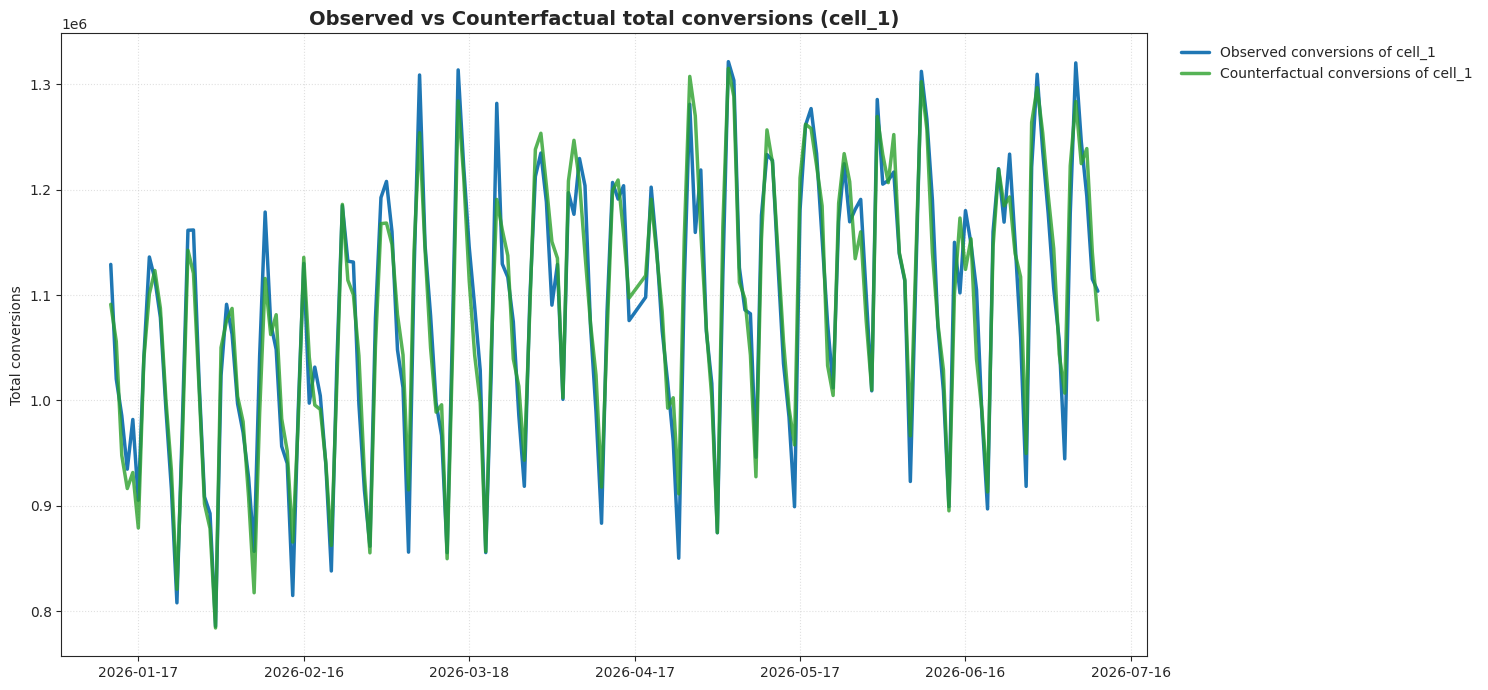

In [14]:
geos_in_design = sorted(set(pre.location) - set(design.excluded_geos))
strata = dict(zip(geos_in_design, np.asarray(design.geo_stratum_labels).astype(int)))
avg = pre.groupby("location").agg(avg_daily_rev=("conversions", "mean"), avg_daily_spend=("spend", "mean"))
rows = []
for g in md.location:
    if g in cell.treatment_geos:
        grp, why = "TREATMENT", "heavy-up +%d%% paid search+social" % (BUDGET_PCT * 100)
    elif g in design.control_geos:
        grp, why = "CONTROL", "business-as-usual spend"
    else:
        grp = "EXCLUDED"
        why = excl.set_index("location").exclusion_reason.get(g, "data-quality (spend>0, zero bookings)")
    rows.append((g, grp, strata.get(g, -1), why))
asg = (pd.DataFrame(rows, columns=["location", "group", "stratum", "reason"])
       .merge(md[["location", "region", "peak_occupancy"]]).merge(avg, on="location").sort_values(["group", "stratum", "location"]))
asg.to_csv(OUT / "assignment_table.csv", index=False)
banner("5. FINAL ASSIGNMENT TABLE")
print(asg.round({"avg_daily_rev": 0, "avg_daily_spend": 0}).to_string(index=False))
print("\ngroup sizes:", asg.group.value_counts().to_dict())
summary = asg.groupby("group").agg(n=("location", "size"), avg_daily_rev=("avg_daily_rev", "sum"), avg_daily_spend=("avg_daily_spend", "sum"))
print(summary.round(0).to_string())
print("\ntreatment-by-stratum balance:")
print(pd.crosstab(asg[asg.group != "EXCLUDED"].stratum, asg[asg.group != "EXCLUDED"].group).to_string())

# persist for stage 3/4
(OUT / "design.json").write_text(design.export_to_json())
reloaded = geox.Design.load_from_json((OUT / "design.json").read_text())
assert reloaded.designs["cell_1"].treatment_geos == cell.treatment_geos

geox.plot_design(design)
for i, n in enumerate(plt.get_fignums(), 1):
    plt.figure(n).savefig(OUT / f"design_pretest_fit_{i}.png", dpi=110, bbox_inches="tight")

##### Visual: duration trade-off, power, and the Control vs Treatment split

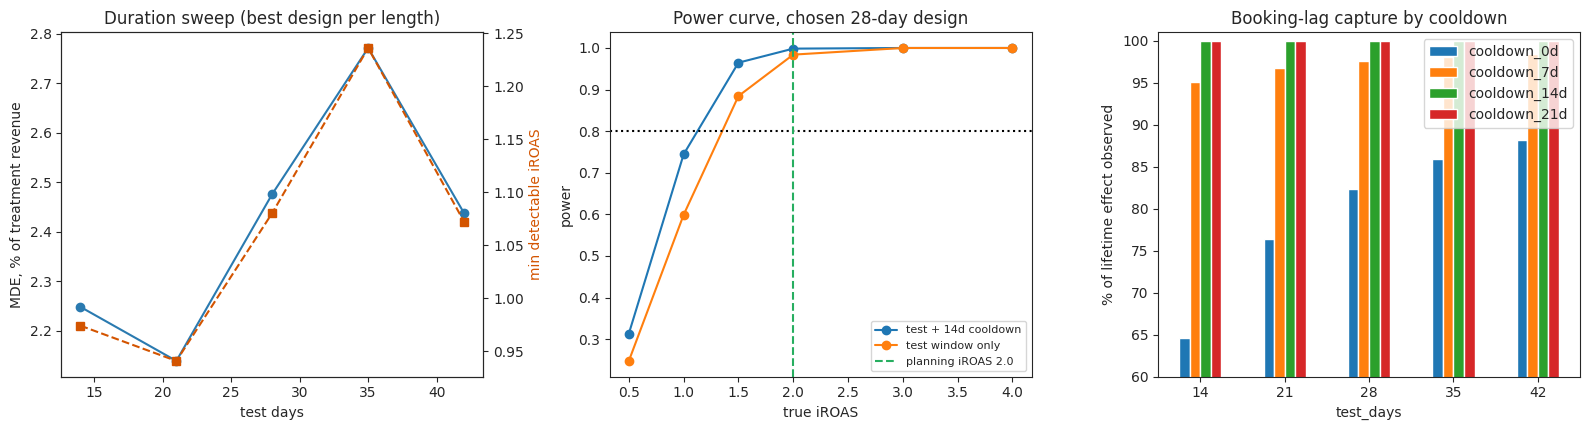

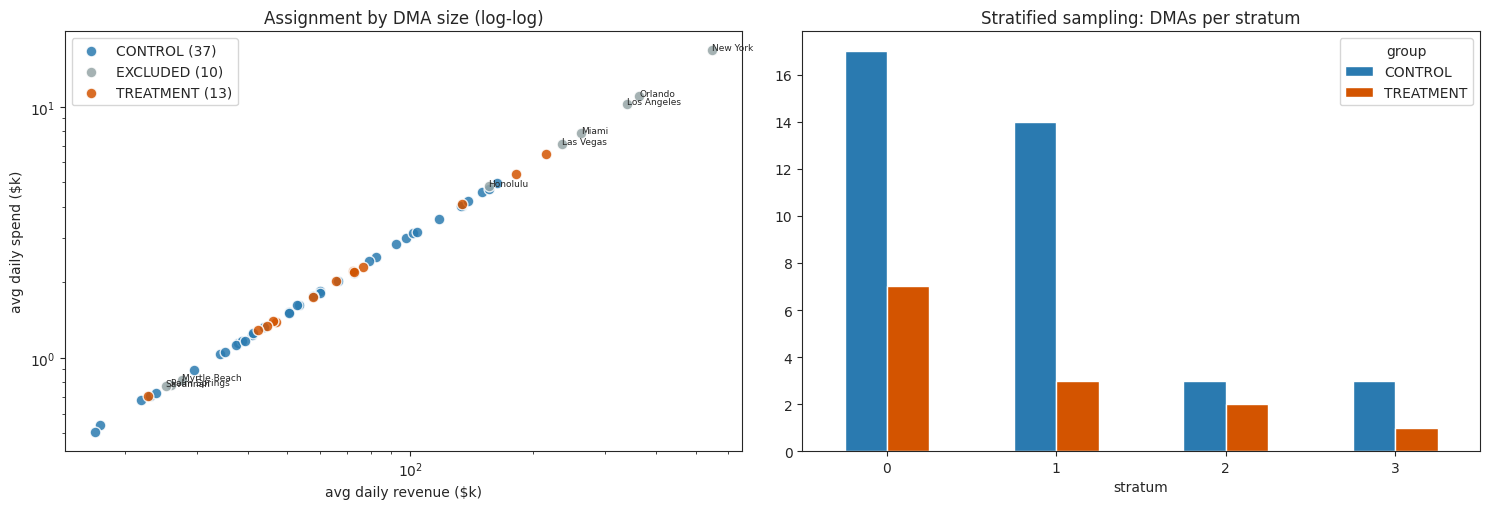

,location,group,stratum,region,reason
0,Albuquerque,CONTROL,0,MT,business-as-usual spend
1,Asheville,CONTROL,0,SE,business-as-usual spend
2,Austin,CONTROL,0,TX,business-as-usual spend
3,Birmingham,CONTROL,0,SE,business-as-usual spend
4,Charleston SC,CONTROL,0,SE,business-as-usual spend
5,Charlotte,CONTROL,0,SE,business-as-usual spend
6,Cleveland,CONTROL,0,MW,business-as-usual spend
7,Colorado Springs,CONTROL,0,MT,business-as-usual spend
8,Denver,CONTROL,0,MT,business-as-usual spend
9,Fort Myers,CONTROL,0,FL,business-as-usual spend


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].plot(sweep.test_days, sweep.mde_pct, "o-", color=C["ctrl"]); ax[0].set_xlabel("test days"); ax[0].set_ylabel("MDE, % of treatment revenue")
ax2 = ax[0].twinx(); ax2.plot(sweep.test_days, sweep.min_detectable_iROAS, "s--", color=C["treat"]); ax2.set_ylabel("min detectable iROAS", color=C["treat"]); ax2.grid(False)
ax[0].set_title("Duration sweep (best design per length)")
for lab, g_ in pw.groupby("read"): ax[1].plot(g_.true_iROAS, g_.power, "o-", label=lab)
ax[1].axhline(.8, color="k", ls=":"); ax[1].axvline(TRUE_IROAS, color=C["good"], ls="--", label="planning iROAS 2.0")
ax[1].set_xlabel("true iROAS"); ax[1].set_ylabel("power"); ax[1].set_title("Power curve, chosen 28-day design"); ax[1].legend(fontsize=8)
cap.set_index("test_days")[["cooldown_0d","cooldown_7d","cooldown_14d","cooldown_21d"]].plot(kind="bar", ax=ax[2], rot=0)
ax[2].set_ylim(60, 101); ax[2].set_ylabel("% of lifetime effect observed"); ax[2].set_title("Booking-lag capture by cooldown")
plt.show()

colors = {"TREATMENT": C["treat"], "CONTROL": C["ctrl"], "EXCLUDED": C["excl"]}
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
for gname, g_ in asg.groupby("group"):
    ax[0].scatter(g_.avg_daily_rev / 1e3, g_.avg_daily_spend / 1e3, s=60, c=colors[gname], label=f"{gname} ({len(g_)})", alpha=.85, edgecolor="w")
for r_ in asg[asg.group == "EXCLUDED"].itertuples(): ax[0].annotate(r_.location, (r_.avg_daily_rev / 1e3, r_.avg_daily_spend / 1e3), fontsize=6.5)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("avg daily revenue ($k)"); ax[0].set_ylabel("avg daily spend ($k)")
ax[0].set_title("Assignment by DMA size (log-log)"); ax[0].legend()
ct = pd.crosstab(asg[asg.group != "EXCLUDED"].stratum, asg[asg.group != "EXCLUDED"].group)
ct.plot(kind="bar", ax=ax[1], color=[colors[c] for c in ct.columns], rot=0)
ax[1].set_title("Stratified sampling: DMAs per stratum"); ax[1].set_xlabel("stratum")
plt.show()
asg[["location","group","stratum","region","reason"]].reset_index(drop=True)

#### Verification

In [16]:
tg, cg = set(cell.treatment_geos), set(design.control_geos)
checks = {
    "no overlap treatment/control": not (tg & cg),
    "operational exclusions respected": not ((tg | cg) & set(excl.location)),
    "broken-tracking geo excluded": BROKEN_TRACKING_GEO not in (tg | cg),
    "A/A p-value >= alpha": cell.p_value >= 0.10,
    "treatment share of revenue <= 30%": final_set.design_metrics.iloc[0].treatment_conversions_pct <= 30.0,
    "design JSON round-trip": True,
    "MDE plausible (0.5%-5% of treatment revenue)": bool(sweep.mde_pct.between(0.5, 5).all()),
    "min detectable iROAS < planning iROAS (2.0)": float(sweep.loc[sweep.test_days == DUR, "min_detectable_iROAS"].iloc[0]) < TRUE_IROAS,
}
# NOTE: pct-MDE is NOT strictly monotone in test length: errors are autocorrelated
# (regional shocks), each duration re-draws its own best candidate, and longer tests
# shorten the training window. Pick duration on the booking cycle, not on this column alone.
banner("VERIFICATION")
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
assert all(checks.values()), "stage-2 verification failed"


VERIFICATION
[PASS] no overlap treatment/control
[PASS] operational exclusions respected
[PASS] broken-tracking geo excluded
[PASS] A/A p-value >= alpha
[PASS] treatment share of revenue <= 30%
[PASS] design JSON round-trip
[PASS] MDE plausible (0.5%-5% of treatment revenue)
[PASS] min detectable iROAS < planning iROAS (2.0)


## Stage 3 — Simulated test + cooldown with a known ground truth

In [17]:
import numpy as np
import pandas as pd

import meridian_geox as geox
from common import *   # noqa: F401,F403

setup_logging()
pd.set_option("display.width", 200)

design = geox.Design.load_from_json((OUT / "design.json").read_text())
treat = sorted(design.designs["cell_1"].treatment_geos)

#### Baseline world: SAME seed as stage 1 => identical history; only test/cooldown are new

In [18]:
world = build_untreated_panel()
world.loc[world.location == BROKEN_TRACKING_GEO, "conversions"] = 0.0     # tracking still broken
pre_clean = pd.read_csv(OUT / "pretest_clean.csv", parse_dates=["date"])
pre_world = split_windows(world)["pretest"]
m = pre_clean.merge(pre_world, on=["date", "location"], suffixes=("", "_w"))
ratio = (m.conversions / m.conversions_w).replace([np.inf], np.nan).dropna()
print(f"sanity: cleaned pre-test vs regenerated baseline  median ratio={ratio.median():.4f} "
      f"(1.0 expected; deviations = injected faults / repairs)")

sanity: cleaned pre-test vs regenerated baseline  median ratio=1.0000 (1.0 expected; deviations = injected faults / repairs)


#### Apply the heavy-up treatment + lagged incremental bookings

In [19]:
rng = np.random.default_rng(SEED + 7)
dates = pd.date_range(PRETEST_START, periods=TOTAL_DAYS)
w_rev = world.pivot(index="date", columns="location", values="conversions")
w_sp = world.pivot(index="date", columns="location", values="spend")
T = len(dates)
in_test = ((dates >= TEST_START) & (dates <= TEST_END))

extra_spend = pd.DataFrame(0.0, index=dates, columns=w_sp.columns)
sd = 0.08
delivery = DELIVERY_FACTOR * rng.lognormal(-sd**2 / 2, sd, (in_test.sum(), len(treat)))   # pacing noise
extra_spend.loc[in_test, treat] = w_sp.loc[in_test, treat].values * HEAVY_UP_PCT * delivery

# lagged response: convolve each geo's extra spend with the booking-lag kernel
incr_rev = pd.DataFrame(0.0, index=dates, columns=w_sp.columns)
for g in treat:
    resp = np.convolve(extra_spend[g].values, LAG_KERNEL)[:T]
    s = 0.15
    incr_rev[g] = TRUE_IROAS * resp * rng.lognormal(-s**2 / 2, s, T)

obs_rev = w_rev + incr_rev
obs_sp = w_sp + extra_spend
panel = (pd.concat({"conversions": obs_rev, "spend": obs_sp}, axis=1).stack(level=1, future_stack=True)
         .rename_axis(["date", "location"]).reset_index())

# stitch: keep the *cleaned* historical pre-test exactly as the analyst would have it
post = panel[panel.date > PRETEST_END]
analysis_data = pd.concat([pre_clean, post[["date", "location", "conversions", "spend"]]], ignore_index=True)
analysis_data = analysis_data.sort_values(["date", "location"]).reset_index(drop=True)
analysis_data.to_csv(OUT / "analysis_data.csv", index=False)

#### Ground truth bookkeeping

In [20]:
tot_spend = float(extra_spend.sum().sum())
mask_test = in_test
rev_test = float(incr_rev.loc[mask_test, treat].sum().sum())
rev_cool = float(incr_rev.loc[dates > TEST_END, treat].sum().sum())
rev_cool7 = float(incr_rev.loc[(dates > TEST_END) & (dates <= TEST_END + pd.Timedelta(days=7)), treat].sum().sum())
truth = dict(
    true_iroas_parameter=TRUE_IROAS,
    realised_iroas_lifetime=(rev_test + rev_cool) / tot_spend,
    realised_iroas_test_window_only=rev_test / tot_spend,
    realised_iroas_test_plus_7d=(rev_test + rev_cool7) / tot_spend,
    incremental_revenue_cooldown_first7d=rev_cool7,
    incremental_spend=tot_spend,
    incremental_revenue_test_window=rev_test,
    incremental_revenue_cooldown=rev_cool,
    share_of_effect_after_test_end=rev_cool / (rev_test + rev_cool),
    treatment_geos=treat,
    test_start=str(TEST_START.date()), test_end=str(TEST_END.date()),
    cooldown_end=str(COOLDOWN_END.date()),
    planned_heavy_up_pct=HEAVY_UP_PCT, delivery_factor=DELIVERY_FACTOR,
)
save_json(truth, OUT / "ground_truth.json")

banner("STAGE 3 - SIMULATED POST-TEST DATA")
print(f"window rows: {len(analysis_data):,}  | {analysis_data.date.min().date()} -> {analysis_data.date.max().date()}")
print(f"test     : {TEST_START.date()} -> {TEST_END.date()} ({TEST_DAYS}d, Sat-Fri, no US holidays)")
print(f"cooldown : {COOLDOWN_START.date()} -> {COOLDOWN_END.date()} ({COOLDOWN_DAYS}d, no extra spend, bookings still landing)")
print(f"treatment DMAs ({len(treat)}): {', '.join(treat)}")
print(pd.Series({k: v for k, v in truth.items() if k not in ("treatment_geos",)}).to_string())

# daily path of the true incremental effect
daily = incr_rev[treat].sum(axis=1)
by_week = daily.groupby(((dates - TEST_START).days // 7)).sum()
print("\ntrue incremental revenue per week since test start ($):")
print(by_week[by_week.index >= 0].round(0).rename_axis("week_since_test_start").to_string())


STAGE 3 - SIMULATED POST-TEST DATA
window rows: 13,320  | 2026-01-12 -> 2026-08-21
test     : 2026-07-11 -> 2026-08-07 (28d, Sat-Fri, no US holidays)
cooldown : 2026-08-08 -> 2026-08-21 (14d, no extra spend, bookings still landing)
treatment DMAs (13): Boise, Chicago, Detroit, Hartford, Houston, Indianapolis, Jacksonville, New Orleans, Providence, Raleigh, Richmond, San Francisco, West Palm Beach
true_iroas_parameter                               2.0
realised_iroas_lifetime                       1.991291
realised_iroas_test_window_only               1.634361
realised_iroas_test_plus_7d                   1.945099
incremental_revenue_cooldown_first7d     204080.809062
incremental_spend                        656763.126308
incremental_revenue_test_window         1073388.288651
incremental_revenue_cooldown             234418.403997
share_of_effect_after_test_end                0.179245
test_start                                  2026-07-11
test_end                                    2026-

##### Visual: the injected ground truth (what a perfect analyst would recover)

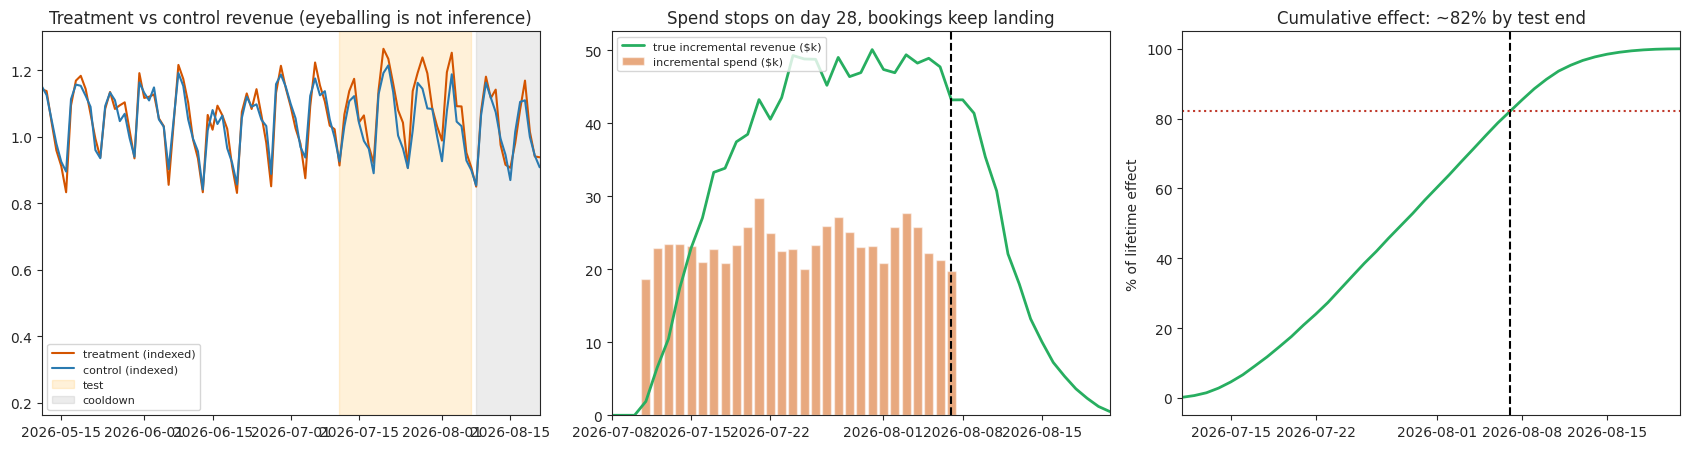

In [21]:
tr_rev = analysis_data[analysis_data.location.isin(treat)].groupby("date").conversions.sum()
co_rev = analysis_data[analysis_data.location.isin(list(design.control_geos))].groupby("date").conversions.sum()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
idx = (tr_rev / tr_rev.loc[:PRETEST_END].mean())
ax[0].plot(idx.index, idx.values, color=C["treat"], label="treatment (indexed)")
idx2 = (co_rev / co_rev.loc[:PRETEST_END].mean()); ax[0].plot(idx2.index, idx2.values, color=C["ctrl"], label="control (indexed)")
ax[0].axvspan(TEST_START, TEST_END, color="orange", alpha=.15, label="test"); ax[0].axvspan(COOLDOWN_START, COOLDOWN_END, color="grey", alpha=.15, label="cooldown")
ax[0].set_xlim(PRETEST_END - pd.Timedelta(days=60), COOLDOWN_END); ax[0].legend(fontsize=8); ax[0].set_title("Treatment vs control revenue (eyeballing is not inference)")
dly = incr_rev[treat].sum(axis=1) / 1e3; sp = extra_spend[treat].sum(axis=1) / 1e3
ax[1].bar(sp.index, sp.values, color=C["treat"], alpha=.5, label="incremental spend ($k)")
ax[1].plot(dly.index, dly.values, color=C["good"], lw=2, label="true incremental revenue ($k)")
ax[1].axvline(TEST_END, color="k", ls="--"); ax[1].set_xlim(TEST_START - pd.Timedelta(days=3), COOLDOWN_END); ax[1].legend(fontsize=8)
ax[1].set_title("Spend stops on day 28, bookings keep landing")
cs = dly.cumsum() / dly.sum() * 100
ax[2].plot(cs.index, cs.values, color=C["good"], lw=2); ax[2].axvline(TEST_END, color="k", ls="--")
ax[2].axhline(100 - 100 * truth["share_of_effect_after_test_end"], color=C["bad"], ls=":")
ax[2].set_xlim(TEST_START, COOLDOWN_END); ax[2].set_ylabel("% of lifetime effect"); ax[2].set_title("Cumulative effect: ~82% by test end")
plt.show()

#### Verification

In [22]:
checks = {
    "lifetime iROAS == parameter (±3%)": abs(truth["realised_iroas_lifetime"] / TRUE_IROAS - 1) < 0.03,
    "all lagged bookings land inside cooldown (nothing after day 14)": float(daily[dates > COOLDOWN_END].sum()) < 1e-6,
    "test-window read under-states effect (lag)": truth["realised_iroas_test_window_only"] < truth["realised_iroas_lifetime"],
    "share after test end in 10-30%": 0.10 < truth["share_of_effect_after_test_end"] < 0.30,
    "control & excluded geos untouched": float(incr_rev.drop(columns=treat).abs().sum().sum()) == 0.0,
    "no extra spend outside the test window": float(extra_spend.loc[~in_test].abs().sum().sum()) == 0.0,
    "geo set matches design": set(analysis_data.location) == set(pre_clean.location),
}
banner("VERIFICATION")
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
assert all(checks.values()), "stage-3 verification failed"


VERIFICATION
[PASS] lifetime iROAS == parameter (±3%)
[PASS] all lagged bookings land inside cooldown (nothing after day 14)
[PASS] test-window read under-states effect (lag)
[PASS] share after test end in 10-30%
[PASS] control & excluded geos untouched
[PASS] no extra spend outside the test window
[PASS] geo set matches design


## Stage 4 — Analysis, estimator comparison, Meridian prior

In [23]:
import warnings

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, stats

import meridian_geox as geox
from common import *   # noqa: F401,F403

warnings.filterwarnings("ignore", message="FigureCanvasAgg")
warnings.filterwarnings("ignore", message="The balance properties of Sobol")
setup_logging()
pd.set_option("display.width", 220, "display.max_columns", 40)

data = pd.read_csv(OUT / "analysis_data.csv", parse_dates=["date"])
design = geox.Design.load_from_json((OUT / "design.json").read_text())
truth = json.loads((OUT / "ground_truth.json").read_text())
ALPHA = 0.10
qc = geox.QualityCheckConfig(exclude_geos_no_response=True, exclude_outlier_dates=True)

#### A. meridian_geox.analyze()

[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.



A0. geox analysis-phase data-quality check
               metric  value
Outlier pretest dates      2
auto-excluded dates: ['2026-04-17', '2026-04-18']


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.


[WARNING] Found outlier pretest dates. Those outlier dates will be removed from design or analysis.



A1. geox.analyze() - TBR, design-aware placebo inference (alpha=0.10 => 90% intervals)
[test] lift $1,280,650  90% CI [382,437, 2,083,617]  p=0.0020 | %lift 4.05% [1.01%, 6.77%] | iROAS 1.941 [0.580, 3.157] sd=0.809
[test+7d] lift $1,313,536  90% CI [112,593, 2,401,316]  p=0.0659 | %lift 3.33% [0.14%, 6.30%] | iROAS 2.004 [0.172, 3.664] sd=1.093
[test+14d] lift $1,408,118  90% CI [-175,619, 2,623,746]  p=0.2335 | %lift 3.00% [-0.56%, 5.75%] | iROAS 2.130 [-0.266, 3.968] sd=1.349
geox auto-excluded geos : ['Fresno', 'Honolulu', 'Las Vegas', 'Los Angeles', 'Miami', 'Myrtle Beach', 'New York', 'Orlando', 'Palm Springs', 'Savannah']
geox auto-excluded dates: ['2026-04-17', '2026-04-18']


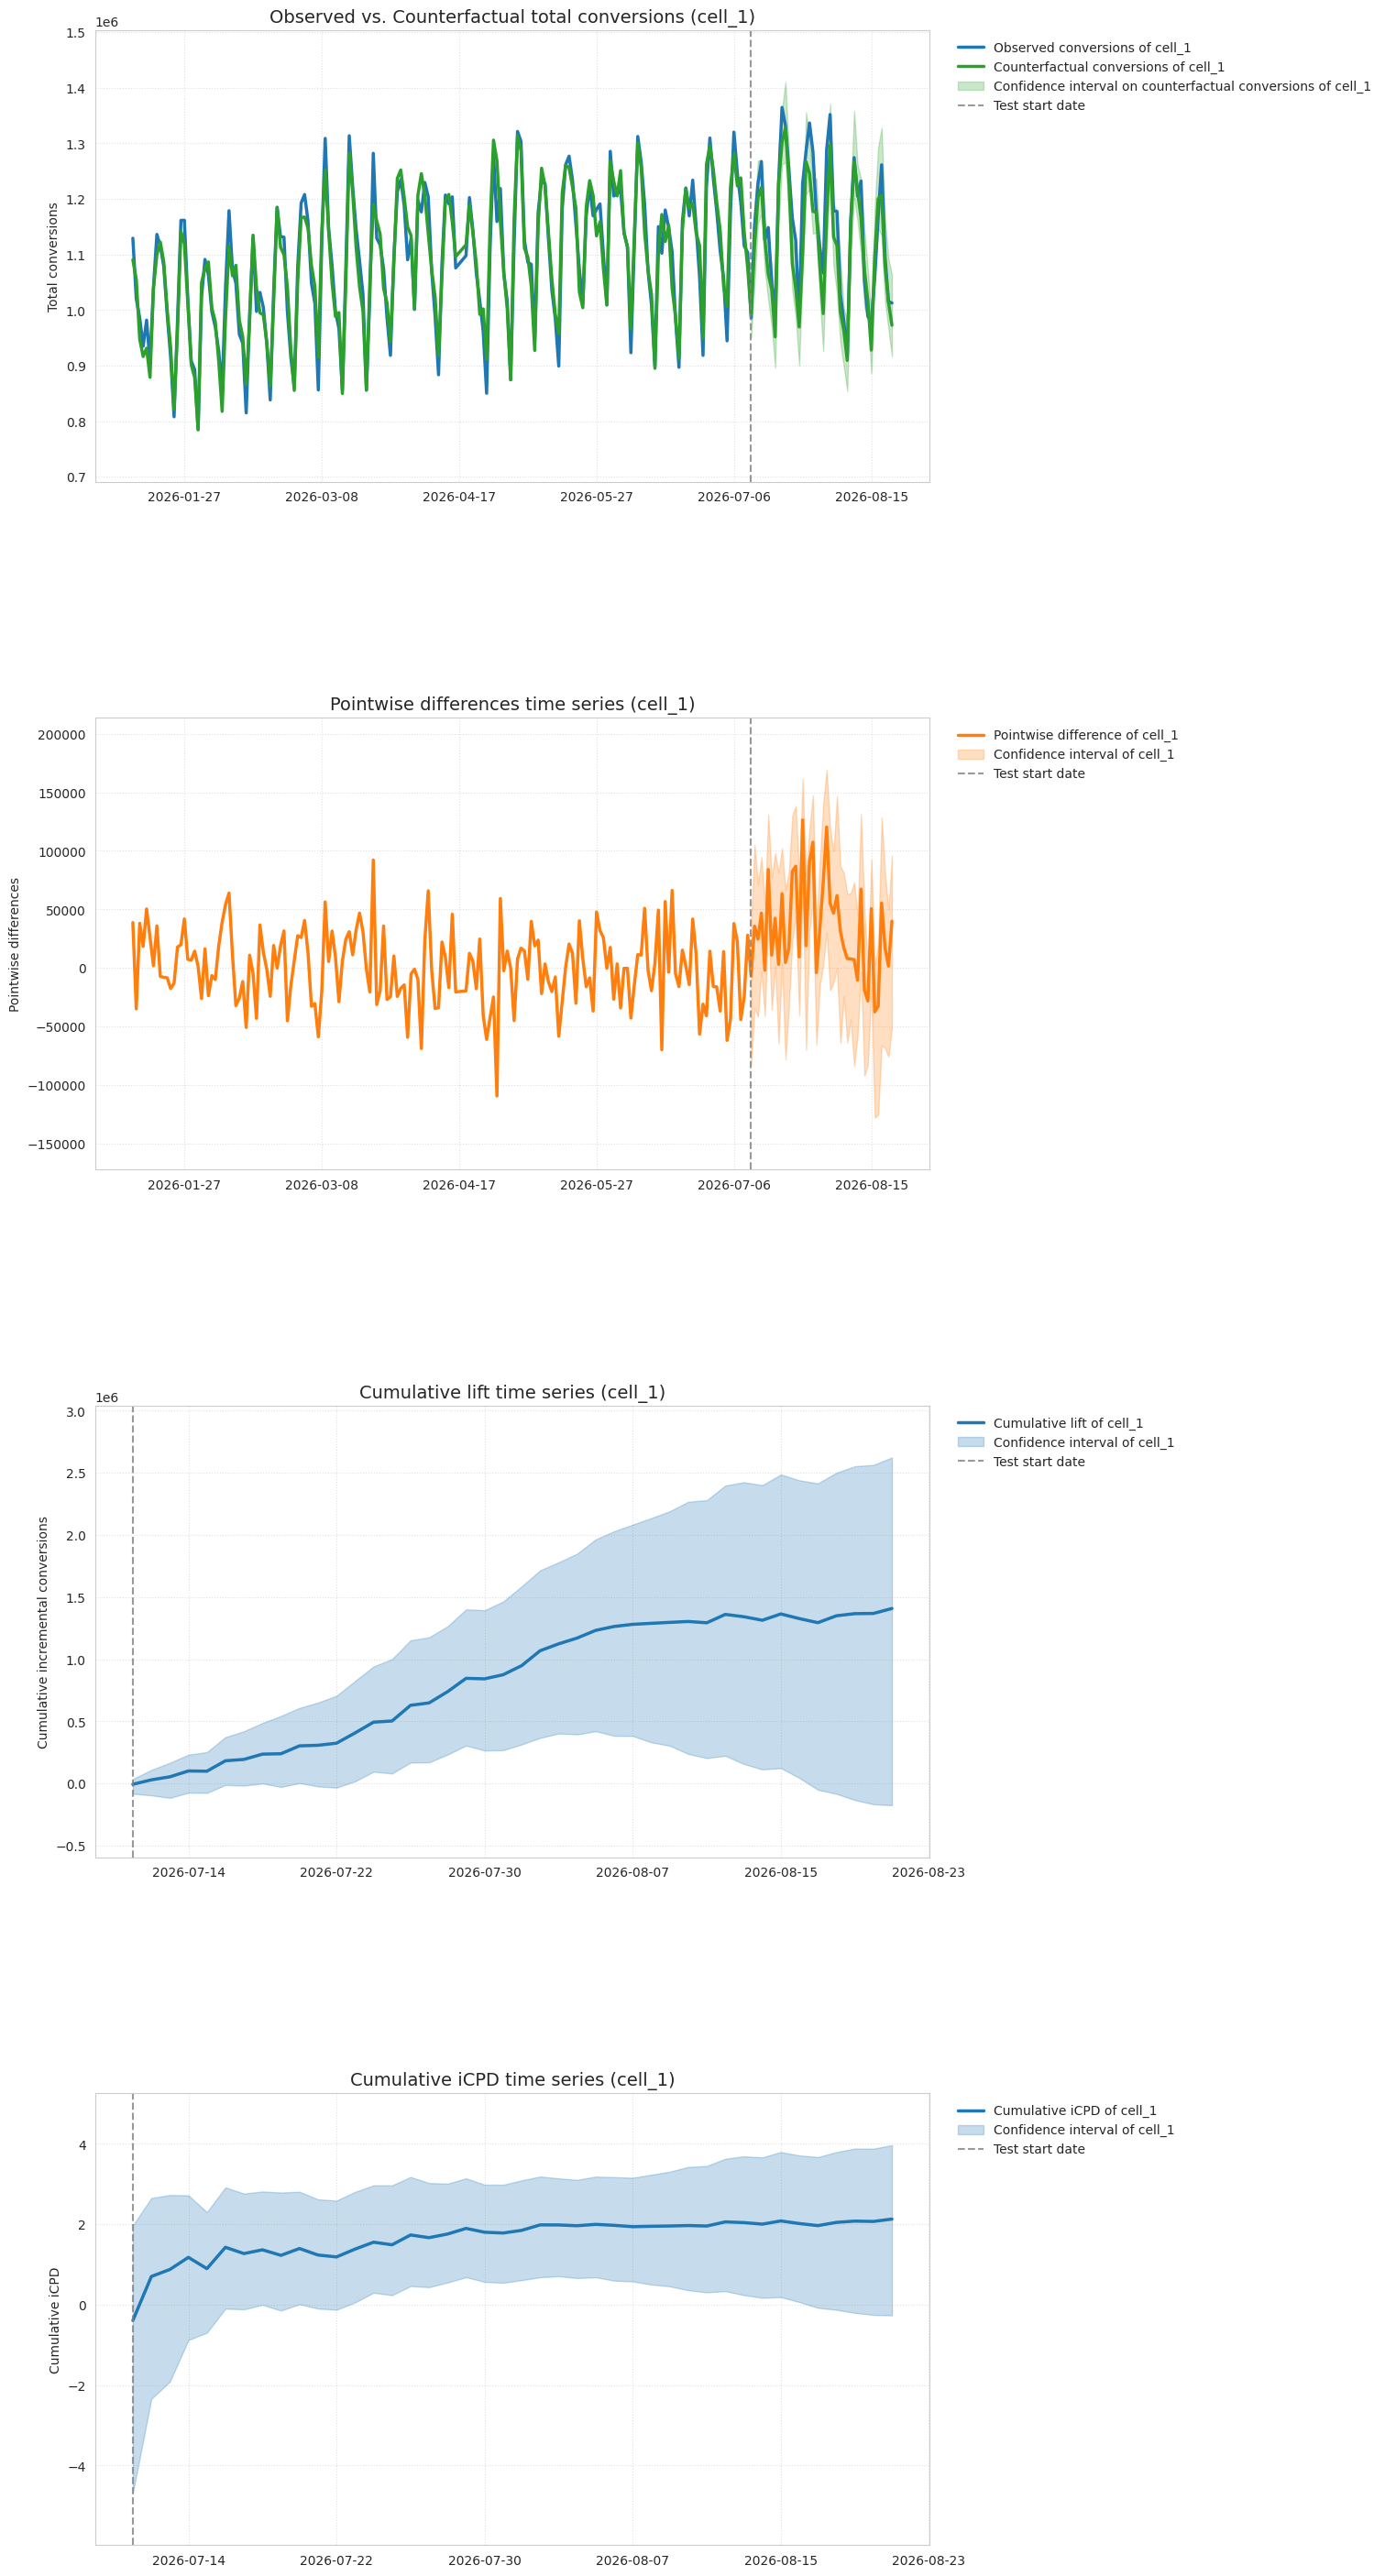

In [24]:
def run_geox(end_date: pd.Timestamp) -> geox.AnalysisResult:
    cfg = geox.AnalysisConfig(design=design, analysis_start_date=TEST_START, analysis_end_date=end_date,
                              alpha=ALPHA, n_placebo_candidates=20_000, n_top_placebos=500, min_placebo_r2=0.6)
    return geox.analyze(data, cfg, qc)


banner("A0. geox analysis-phase data-quality check")
chk_cfg = geox.AnalysisConfig(design=design, analysis_start_date=TEST_START, analysis_end_date=TEST_END)
qcr = geox.check_analysis_data_quality(data, chk_cfg, qc)
print(qcr.quality_metrics[["metric", "value"]].to_string(index=False) if len(qcr.quality_metrics) else "clean")
print("auto-excluded dates:", sorted(str(d.date()) for d in qcr.outlier_dates))

res_test = run_geox(TEST_END)
res_7d = run_geox(TEST_END + pd.Timedelta(days=7))
res_full = run_geox(COOLDOWN_END)


def est_row(name, window, lift, inc_spend, truth_rev, truth_iroas, extra=None):
    """lift: (point, lo, hi, p); inc_spend: scalar; returns a dict with iROAS."""
    p, lo, hi, pv = lift
    r = dict(method=name, window=window, lift_usd=p, lift_lo=lo, lift_hi=hi, p_value=pv,
             incr_spend=inc_spend, iROAS=p / inc_spend, iROAS_lo=lo / inc_spend, iROAS_hi=hi / inc_spend,
             true_iROAS=truth_iroas, true_lift=truth_rev)
    r["covers_truth"] = r["iROAS_lo"] <= truth_iroas <= r["iROAS_hi"]
    return r


def geox_row(res, window, truth_rev, truth_iroas):
    m = res.results["cell_1"]
    inc_spend = m.lift.point_estimate / m.icpd.point_estimate
    r = est_row("geox TBR", window, (m.lift.point_estimate, m.lift.lower_bound, m.lift.upper_bound, m.lift.p_value),
                inc_spend, truth_rev, truth_iroas)
    # use geox's own iCPD interval (identical in construction) rather than re-deriving it
    r.update(iROAS=m.icpd.point_estimate, iROAS_lo=m.icpd.lower_bound, iROAS_hi=m.icpd.upper_bound)
    r["covers_truth"] = r["iROAS_lo"] <= truth_iroas <= r["iROAS_hi"]
    r["pct_lift"] = 100 * m.percent_lift.point_estimate
    return r


T_REV = {"test": truth["incremental_revenue_test_window"],
         "test+7d": truth["incremental_revenue_test_window"] + truth["incremental_revenue_cooldown_first7d"],
         "test+14d": truth["incremental_revenue_test_window"] + truth["incremental_revenue_cooldown"]}
T_ROAS = {"test": truth["realised_iroas_test_window_only"], "test+7d": truth["realised_iroas_test_plus_7d"],
          "test+14d": truth["realised_iroas_lifetime"]}
rows = [geox_row(res_test, "test", T_REV["test"], T_ROAS["test"]),
        geox_row(res_7d, "test+7d", T_REV["test+7d"], T_ROAS["test+7d"]),
        geox_row(res_full, "test+14d", T_REV["test+14d"], T_ROAS["test+14d"])]

banner("A1. geox.analyze() - TBR, design-aware placebo inference (alpha=0.10 => 90% intervals)")
for w, r_ in (("test", res_test), ("test+7d", res_7d), ("test+14d", res_full)):
    m = r_.results["cell_1"]
    print(f"[{w}] lift ${m.lift.point_estimate:,.0f}  90% CI [{m.lift.lower_bound:,.0f}, {m.lift.upper_bound:,.0f}]  "
          f"p={m.lift.p_value:.4f} | %lift {100*m.percent_lift.point_estimate:.2f}% "
          f"[{100*m.percent_lift.lower_bound:.2f}%, {100*m.percent_lift.upper_bound:.2f}%] | "
          f"iROAS {m.icpd.point_estimate:.3f} [{m.icpd.lower_bound:.3f}, {m.icpd.upper_bound:.3f}] sd={m.icpd.standard_deviation:.3f}")
print("geox auto-excluded geos :", sorted(res_full.excluded_geos))
print("geox auto-excluded dates:", sorted(str(d.date()) for d in res_full.excluded_dates))

geox.plot_analysis(res_full)
for i, n in enumerate(plt.get_fignums(), 1):
    plt.figure(n).savefig(OUT / f"analysis_tbr_{i}.png", dpi=110, bbox_inches="tight")
plt.show()

##### Visual: geox TBR output (counterfactual, cumulative lift)

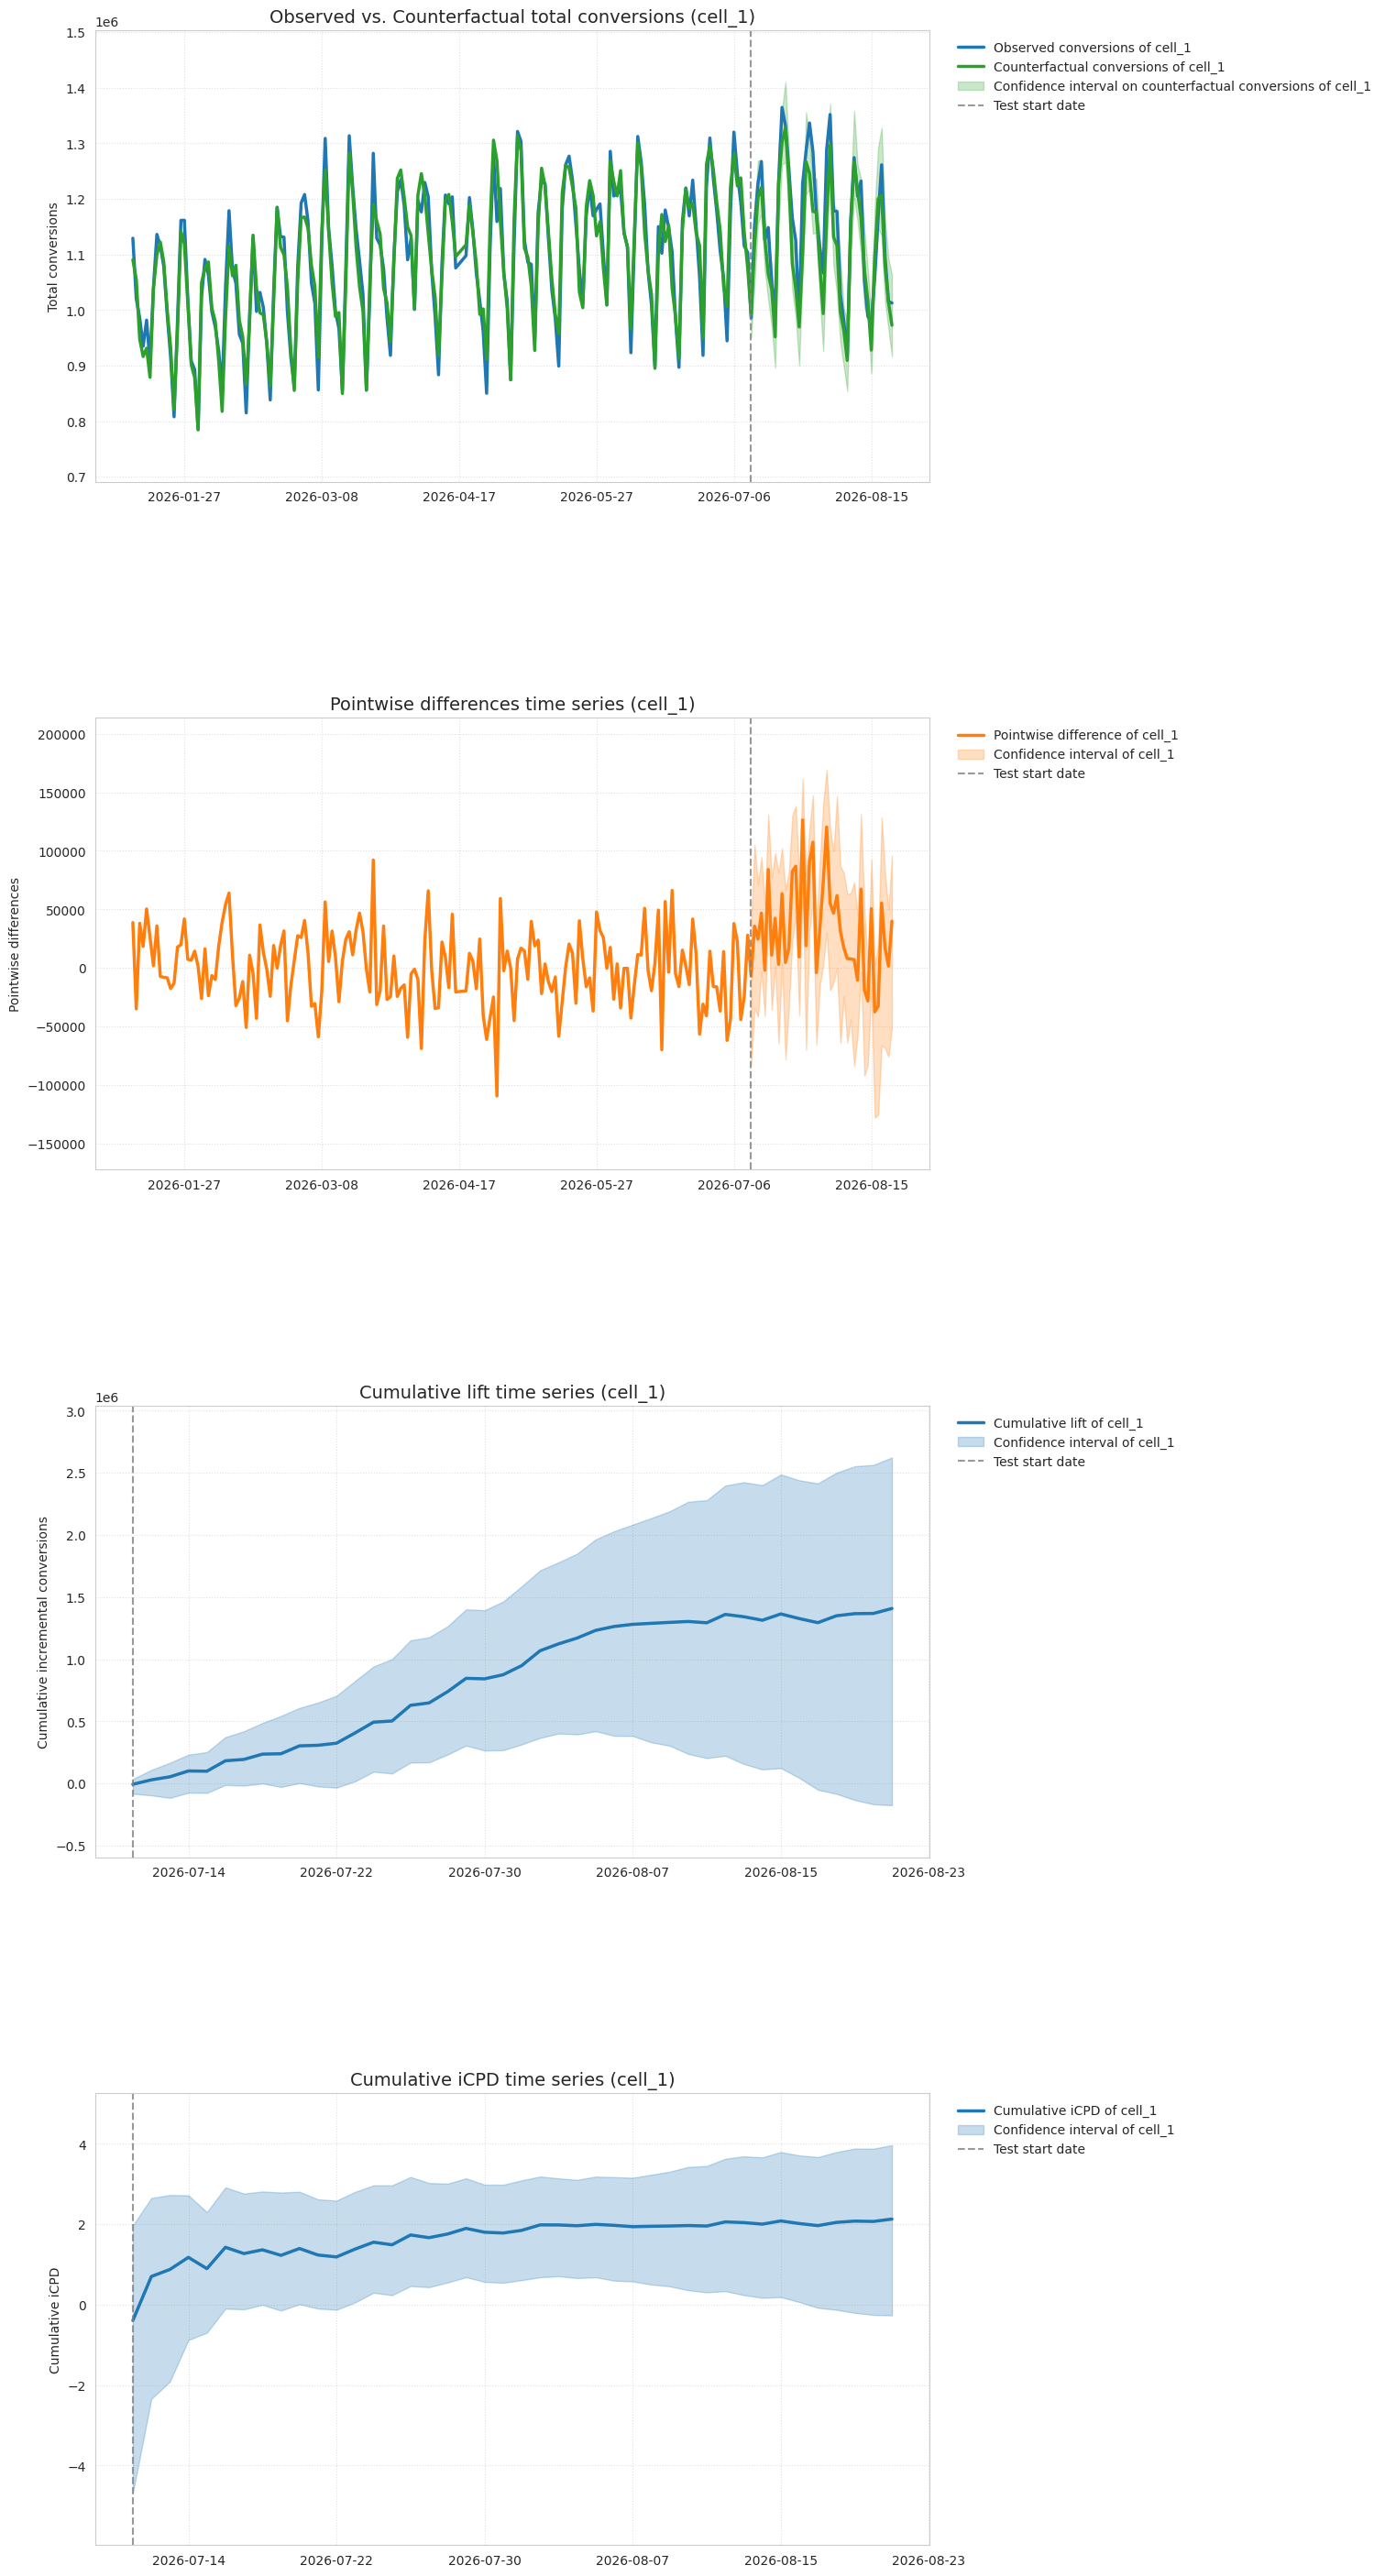

In [25]:
geox.plot_analysis(res_full)
plt.show()

#### B. Reference SC / SDID with design-aware placebo inference

In [26]:
excl_dates = {pd.Timestamp(d) for d in res_full.excluded_dates}
excl_geos = set(res_full.excluded_geos)
use = data[~data.location.isin(excl_geos) & ~data.date.isin(excl_dates)]
Y = use.pivot(index="date", columns="location", values="conversions")
S = use.pivot(index="date", columns="location", values="spend")
treated = sorted(design.designs["cell_1"].treatment_geos)
controls = sorted(set(Y.columns) - set(treated))
geos_design = sorted(set(data.location) - set(design.excluded_geos))
strat = dict(zip(geos_design, np.asarray(design.geo_stratum_labels).astype(int)))
PRE_LEN = 126                                                     # 18 whole weeks of local history
pre_idx = Y.index[Y.index < TEST_START][-PRE_LEN:]
win = {"test": Y.index[(Y.index >= TEST_START) & (Y.index <= TEST_END)],
       "test+14d": Y.index[(Y.index >= TEST_START) & (Y.index <= COOLDOWN_END)]}


def simplex_ls(A, b, ridge=0.0):
    """min ||A w - b||^2 + ridge ||w||^2  s.t. w >= 0, sum w = 1."""
    n = A.shape[1]
    AtA, Atb = A.T @ A + ridge * np.eye(n), A.T @ b
    f = lambda w: w @ AtA @ w - 2 * Atb @ w
    g = lambda w: 2 * (AtA @ w - Atb)
    r = optimize.minimize(f, np.full(n, 1 / n), jac=g, bounds=[(0, 1)] * n, method="SLSQP",
                          constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}],
                          options={"maxiter": 200, "ftol": 1e-12})
    return r.x


def sc_weights(Ypre_c, ypre_t):
    return simplex_ls(Ypre_c.T, ypre_t)


def sdid_unit_weights(Ypre_c, ypre_t, n_tr, t_post):
    sigma = np.diff(Ypre_c, axis=1).std()
    zeta2 = (n_tr * t_post) ** 0.5 * sigma ** 2                         # zeta^2 = (N_tr T_post)^(1/2) sigma^2
    A = (Ypre_c - Ypre_c.mean(1, keepdims=True)).T
    return simplex_ls(A, ypre_t - ypre_t.mean(), ridge=zeta2 * A.shape[0])     # zeta^2 * T_pre * ||w||^2


def sdid_time_weights(Ypre_c, Ypost_c):
    M = Ypre_c - Ypre_c.mean(0, keepdims=True)                          # remove unit-mean (lambda_0)
    b = Ypost_c.mean(1) - Ypost_c.mean(1).mean()
    return simplex_ls(M, b, ridge=1e-9 * (M ** 2).sum())


def effects(df, tr, co, wname, which="both"):
    """Per-day average effect on the treated group under SC and SDID, for window `wname`."""
    pre = df.loc[pre_idx]
    post = df.loc[win[wname]]
    Ypre_c, Ypost_c = pre[co].values.T, post[co].values.T              # (N_co, T)
    ypre_t, ypost_t = pre[tr].values.mean(1), post[tr].values.mean(1)
    scale = Ypre_c.mean()
    Ypre_c, Ypost_c, ypre_t, ypost_t = (a / scale for a in (Ypre_c, Ypost_c, ypre_t, ypost_t))
    w_sc = sc_weights(Ypre_c, ypre_t)
    e_sc = (ypost_t - w_sc @ Ypost_c) * scale
    om = sdid_unit_weights(Ypre_c, ypre_t, len(tr), Ypost_c.shape[1])
    lam = sdid_time_weights(Ypre_c, Ypost_c)
    e_sd = ((ypost_t - lam @ ypre_t) - (om @ Ypost_c - lam @ (om @ Ypre_c))) * scale
    return e_sc, e_sd


def run_estimators(df, tr, co):
    """Return {(method, window): total effect over window} for a treated/control split."""
    out = {}
    for wname in win:
        e_sc, e_sd = effects(df, tr, co, wname)
        out[("SC (custom)", wname)] = len(tr) * e_sc.sum()
        out[("SDID (custom)", wname)] = len(tr) * e_sd.sum()
    return out


def placebo_split(rng):
    """Design-aware placebo: stratified sampling over the CONTROL pool with the design's stratum labels.

    Same total group size as the real treatment group, allocated proportionally to each stratum's share of
    the control pool (largest-remainder rounding) - the same rule geox uses to draw its own placebo splits.
    Copying the real treated stratum counts would be wrong: they were drawn from treated+control geos together,
    so applying them to controls alone over-samples small strata and biases the placebo distribution.
    """
    pools = {s: [g for g in controls if strat[g] == s] for s in sorted({strat[g] for g in controls})}
    share = {s: len(p) * len(treated) / len(controls) for s, p in pools.items()}
    alloc = {s: int(np.floor(v)) for s, v in share.items()}
    for s in sorted(share, key=lambda s: share[s] - alloc[s], reverse=True)[: len(treated) - sum(alloc.values())]:
        alloc[s] += 1
    pick = []
    for s, k in alloc.items():
        pick += list(rng.choice(pools[s], size=k, replace=False))
    return sorted(pick)


import time
t0 = time.time()
real_rev = run_estimators(Y, treated, controls)
real_sp = run_estimators(S, treated, controls)
print(f"\n[timing] one SC+SDID pass over both windows: {time.time()-t0:.1f}s")

def holdout_r2(tr, co):
    """Out-of-sample R^2 of the SC fit: weights from the older pre-test days, scored on the last TEST_DAYS pre days
    (mirrors geox's `min_placebo_r2` filter, which keeps only splits whose control predicts treatment well)."""
    fit_idx, ho_idx = pre_idx[:-TEST_DAYS], pre_idx[-TEST_DAYS:]
    A, b = Y.loc[fit_idx, co].values, Y.loc[fit_idx, tr].values.mean(1)
    s = A.mean()
    w = sc_weights((A / s).T, b / s)
    y, yhat = Y.loc[ho_idx, tr].values.mean(1), Y.loc[ho_idx, co].values @ w
    return 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum()


# Design-aware placebos: (1) stratified draws with the real stratum mix, (2) keep the best-fitting quartile+,
# because the real treatment group was ALSO chosen as a well-matched split out of tens of thousands of candidates.
N_DRAW, K = 500, 150
rng = np.random.default_rng(2026)
draws = [placebo_split(rng) for _ in range(N_DRAW)]
r2s = np.array([holdout_r2(pt, [g for g in controls if g not in pt]) for pt in draws])
r2_real = holdout_r2(treated, controls)
keep = np.argsort(-r2s)[:K]
print(f"\nholdout R^2 - real treatment group: {r2_real:.3f} | all {N_DRAW} placebo draws: median {np.median(r2s):.3f} "
      f"| kept top {K}: min {r2s[keep].min():.3f}, median {np.median(r2s[keep]):.3f}")
plc = {k: [] for k in real_rev}
for i in keep:
    pt = draws[i]
    pc = [g for g in controls if g not in pt]
    for k, v in run_estimators(Y, pt, pc).items():
        plc[k].append(v)
print(f"[timing] total incl. {N_DRAW} draws / {K} kept placebos: {time.time()-t0:.1f}s")

banner("B0. PLACEBO NULL DISTRIBUTIONS (true effect = 0 by construction) vs. observed effect, $ revenue over window")
diag = []
for (meth, w), lift in real_rev.items():
    e = np.array(plc[(meth, w)])
    diag.append(dict(method=meth, window=w, placebo_mean=e.mean(), placebo_median=np.median(e), placebo_sd=e.std(),
                     p05=np.quantile(e, .05), p95=np.quantile(e, .95), observed=lift, observed_z=(lift - e.mean()) / e.std()))
print(pd.DataFrame(diag).round(0).to_string(index=False))

for (meth, w), lift in real_rev.items():
    e = np.array(plc[(meth, w)])
    lo, hi = lift - np.quantile(e, 1 - ALPHA / 2), lift - np.quantile(e, ALPHA / 2)     # placebo-error inversion
    pv = (1 + np.sum(np.abs(e) >= abs(lift))) / (1 + K)
    rows.append(est_row(meth, w, (lift, lo, hi, pv), real_sp[(meth, w)], T_REV[w], T_ROAS[w]))

res = pd.DataFrame(rows)
banner("B. ESTIMATOR COMPARISON (90% intervals; truth = what the simulator actually delivered in that window)")
show = res[["method", "window", "lift_usd", "lift_lo", "lift_hi", "p_value", "incr_spend", "iROAS", "iROAS_lo", "iROAS_hi",
            "true_iROAS", "covers_truth"]].copy()
for c in ("lift_usd", "lift_lo", "lift_hi", "incr_spend"):
    show[c] = show[c].round(0).astype(int)
print(show.round({"iROAS": 3, "iROAS_lo": 3, "iROAS_hi": 3, "true_iROAS": 3, "p_value": 4}).to_string(index=False))
res.to_csv(OUT / "estimator_comparison.csv", index=False)
res["bias_pct"] = 100 * (res.iROAS / res.true_iROAS - 1)
print("\nbias vs truth (%):")
print(res.pivot(index="method", columns="window", values="bias_pct").round(1).to_string())


[timing] one SC+SDID pass over both windows: 0.5s



holdout R^2 - real treatment group: 0.882 | all 500 placebo draws: median 0.795 | kept top 150: min 0.823, median 0.845


[timing] total incl. 500 draws / 150 kept placebos: 62.9s

B0. PLACEBO NULL DISTRIBUTIONS (true effect = 0 by construction) vs. observed effect, $ revenue over window
       method   window  placebo_mean  placebo_median  placebo_sd        p05      p95  observed  observed_z
  SC (custom)     test       10746.0        -18814.0    331971.0  -493993.0 601582.0 1312782.0         4.0
SDID (custom)     test       -9093.0         25671.0    346371.0  -596509.0 526224.0 1333938.0         4.0
  SC (custom) test+14d       34920.0         10981.0    479527.0  -681866.0 994361.0 1487166.0         3.0
SDID (custom) test+14d     -142380.0       -183913.0    530965.0 -1025008.0 659638.0 1346631.0         3.0

B. ESTIMATOR COMPARISON (90% intervals; truth = what the simulator actually delivered in that window)
       method   window  lift_usd  lift_lo  lift_hi  p_value  incr_spend  iROAS  iROAS_lo  iROAS_hi  true_iROAS  covers_truth
     geox TBR     test   1280650   382437  2083617   0.0020      65993

##### Visual: placebo null distributions vs. the observed effect

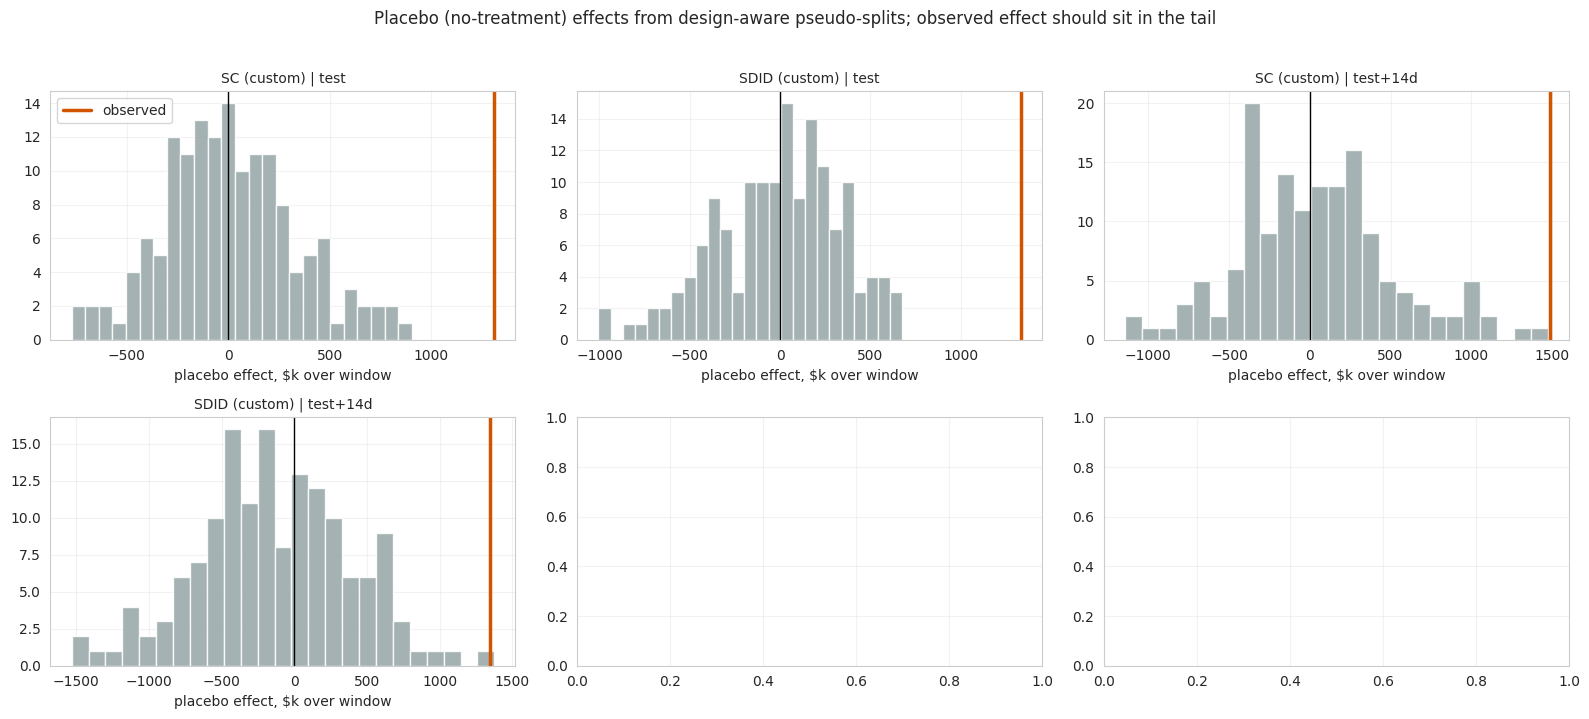

In [27]:
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for a, ((meth, w), lift) in zip(ax.ravel(), real_rev.items()):
    e = np.array(plc[(meth, w)]) / 1e3
    a.hist(e, bins=25, color=C["excl"], alpha=.85)
    a.axvline(lift / 1e3, color=C["treat"], lw=2.5, label="observed")
    a.axvline(0, color="k", lw=1)
    a.set_title(f"{meth} | {w}", fontsize=10); a.set_xlabel("placebo effect, $k over window")
ax[0, 0].legend()
fig.suptitle("Placebo (no-treatment) effects from design-aware pseudo-splits; observed effect should sit in the tail", y=1.02)
plt.show()

#### C. iROAS -> Meridian ROI prior

In [28]:
banner("C. MERIDIAN MMM CALIBRATION - iROAS to roi_m LogNormal prior")
import tensorflow_probability as tfp
from meridian.model import prior_distribution as pdist
from meridian.model import spec

tfd = tfp.distributions
prim = res[(res.method == "geox TBR") & (res.window == "test+14d")].iloc[0]
m = res_full.results["cell_1"].icpd
print(f"PRIMARY experiment read (pre-specified: test + full 14d cooldown, unbiased for the lag):\n"
      f"  iROAS {m.point_estimate:.3f}  90% CI [{m.lower_bound:.3f}, {m.upper_bound:.3f}]  sd={m.standard_deviation:.3f}")


def lognormal_prior(est: geox.Estimate, inflate: float = 1.0):
    """iROAS Estimate -> LogNormal(mu, sigma) for Meridian's roi_m.

    * CI strictly positive  -> match the 90% interval to the prior's 5th/95th percentiles
      (Meridian helper `lognormal_dist_from_range`; median = geometric mid-point of the CI).
    * CI reaches <= 0       -> log of a negative bound is undefined, so match mean and sd
      (`lognormal_dist_from_mean_std`) using the point estimate and geox's standard deviation.
    `inflate` widens sigma to hedge the gap between a 4-week snapshot and the whole MMM window.
    """
    if est.lower_bound > 0:
        d, how = pdist.lognormal_dist_from_range(est.lower_bound, est.upper_bound, mass_percent=1 - ALPHA), "range-matched"
    else:
        d, how = pdist.lognormal_dist_from_mean_std(max(est.point_estimate, 1e-3), est.standard_deviation), "moment-matched"
    return tfd.LogNormal(loc=d.loc, scale=d.scale * inflate), how


INFLATE = 1.25          # a 4-week snapshot vs. a multi-year MMM: seasonality, saturation, marginal-vs-average ROI
m7 = res_7d.results["cell_1"].icpd
prior_q, how_q = lognormal_prior(m)                    # primary read, as measured
prior_w, how_w = lognormal_prior(m, INFLATE)           # RECOMMENDED: primary read, widened
prior_7, how_7 = lognormal_prior(m7)                   # sensitivity: test + 7d cooldown read
cands = [("primary test+14d, as measured", prior_q, how_q), (f"primary test+14d x{INFLATE} sigma (RECOMMENDED)", prior_w, how_w),
         ("sensitivity: test+7d read", prior_7, how_7)]
q = [0.05, 0.50, 0.95]
tbl = pd.DataFrame({
    "prior": [c[0] for c in cands], "method": [c[2] for c in cands],
    "mu": [float(c[1].loc) for c in cands], "sigma": [float(c[1].scale) for c in cands],
    "mean": [float(c[1].mean()) for c in cands],
    "p05": [float(c[1].quantile(q[0])) for c in cands], "p50": [float(c[1].quantile(q[1])) for c in cands],
    "p95": [float(c[1].quantile(q[2])) for c in cands],
    "P(prior>truth)": [float(1 - c[1].cdf(truth['realised_iroas_lifetime'])) for c in cands],
})
print(tbl.round(4).to_string(index=False))

roi_prior = pdist.PriorDistribution(roi_m=prior_w)                       # broadcast to every paid channel
model_spec = spec.ModelSpec(prior=roi_prior)                              # media_prior_type defaults to 'roi'
print("\nPriorDistribution(roi_m=LogNormal(mu=%.4f, sigma=%.4f)) built; ModelSpec ok: %s"
      % (float(prior_w.loc), float(prior_w.scale), type(model_spec).__name__))
print("\n--- paste into your Meridian pipeline ---")
print(f"""import tensorflow_probability as tfp
from meridian.model import prior_distribution, spec
prior = prior_distribution.PriorDistribution(
    roi_m=tfp.distributions.LogNormal({float(prior_w.loc):.4f}, {float(prior_w.scale):.4f}))   # paid search + paid social
model_spec = spec.ModelSpec(prior=prior)   # media_prior_type='roi' (default)
# optional: restrict the prior to the test weeks via ModelSpec(roi_calibration=...) (CalibrationSpec)""")


C. MERIDIAN MMM CALIBRATION - iROAS to roi_m LogNormal prior


I0000 00:00:1794524607.291081   16097 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794524608.122260   16097 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/home/rama/miniforge3/envs/mmm-meridian/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PRIMARY experiment read (pre-specified: test + full 14d cooldown, unbiased for the lag):
  iROAS 2.130  90% CI [-0.266, 3.968]  sd=1.349


                                     prior         method      mu  sigma   mean    p05    p50    p95  P(prior>truth)
             primary test+14d, as measured moment-matched  0.5873 0.5808 2.1298 0.6921 1.7992 4.6774          0.4307
primary test+14d x1.25 sigma (RECOMMENDED) moment-matched  0.5873 0.7261 2.3418 0.5450 1.7992 5.9394          0.4444
                 sensitivity: test+7d read  range-matched -0.2314 0.9302 1.2229 0.1718 0.7934 3.6641          0.1613



PriorDistribution(roi_m=LogNormal(mu=0.5873, sigma=0.7261)) built; ModelSpec ok: ModelSpec

--- paste into your Meridian pipeline ---
import tensorflow_probability as tfp
from meridian.model import prior_distribution, spec
prior = prior_distribution.PriorDistribution(
    roi_m=tfp.distributions.LogNormal(0.5873, 0.7261))   # paid search + paid social
model_spec = spec.ModelSpec(prior=prior)   # media_prior_type='roi' (default)
# optional: restrict the prior to the test weeks via ModelSpec(roi_calibration=...) (CalibrationSpec)


##### Visual: estimators with 90% CI vs. window-specific truth, and the Meridian prior

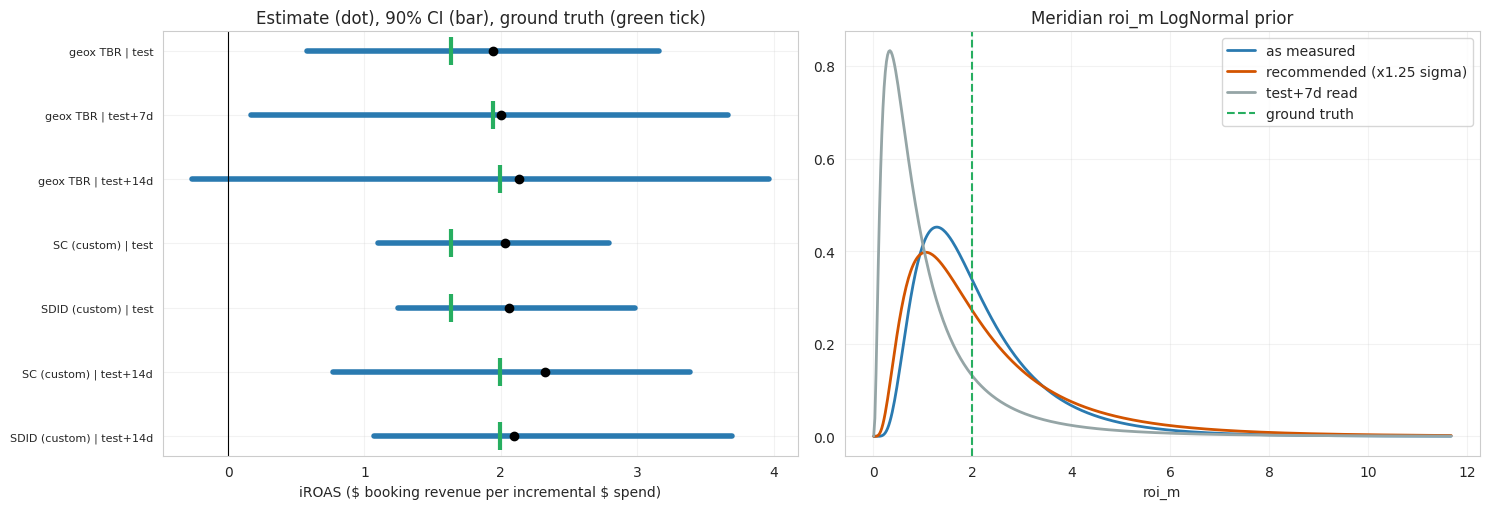

,method,window,iROAS,iROAS_lo,iROAS_hi,true_iROAS,p_value,covers_truth
0,geox TBR,test,1.941,0.580,3.157,1.634,0.002,True
1,geox TBR,test+7d,2.004,0.172,3.664,1.945,0.066,True
2,geox TBR,test+14d,2.130,-0.266,3.968,1.991,0.234,True
3,SC (custom),test,2.028,1.099,2.791,1.634,0.007,True
4,SDID (custom),test,2.062,1.248,2.984,1.634,0.007,True
5,SC (custom),test+14d,2.323,0.770,3.389,1.991,0.007,True
6,SDID (custom),test+14d,2.099,1.071,3.697,1.991,0.033,True


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
y_ = np.arange(len(res))[::-1]
for yi, r in zip(y_, res.itertuples()):
    ax[0].plot([r.iROAS_lo, r.iROAS_hi], [yi, yi], lw=4, color=C["ctrl"] if r.covers_truth else C["bad"], solid_capstyle="round")
    ax[0].plot(r.iROAS, yi, "o", color="k"); ax[0].plot(r.true_iROAS, yi, "|", color=C["good"], ms=20, mew=3)
ax[0].axvline(0, color="k", lw=.8)
ax[0].set_yticks(y_); ax[0].set_yticklabels([f"{r.method} | {r.window}" for r in res.itertuples()], fontsize=8)
ax[0].set_xlabel(r"iROAS (\$ booking revenue per incremental \$ spend)"); ax[0].set_title("Estimate (dot), 90% CI (bar), ground truth (green tick)")
xs = np.linspace(0.01, max(6.0, float(prior_w.quantile(0.995))), 500)
for d, nm, c in ((prior_q, "as measured", C["ctrl"]), (prior_w, "recommended (x1.25 sigma)", C["treat"]), (prior_7, "test+7d read", C["excl"])):
    ax[1].plot(xs, d.prob(xs), label=nm, color=c, lw=2)
ax[1].axvline(truth["realised_iroas_lifetime"], color=C["good"], ls="--", label="ground truth")
ax[1].set_xlabel("roi_m"); ax[1].set_title("Meridian roi_m LogNormal prior"); ax[1].legend()
plt.show()
res[["method","window","iROAS","iROAS_lo","iROAS_hi","true_iROAS","p_value","covers_truth"]].round(3)

#### Figures

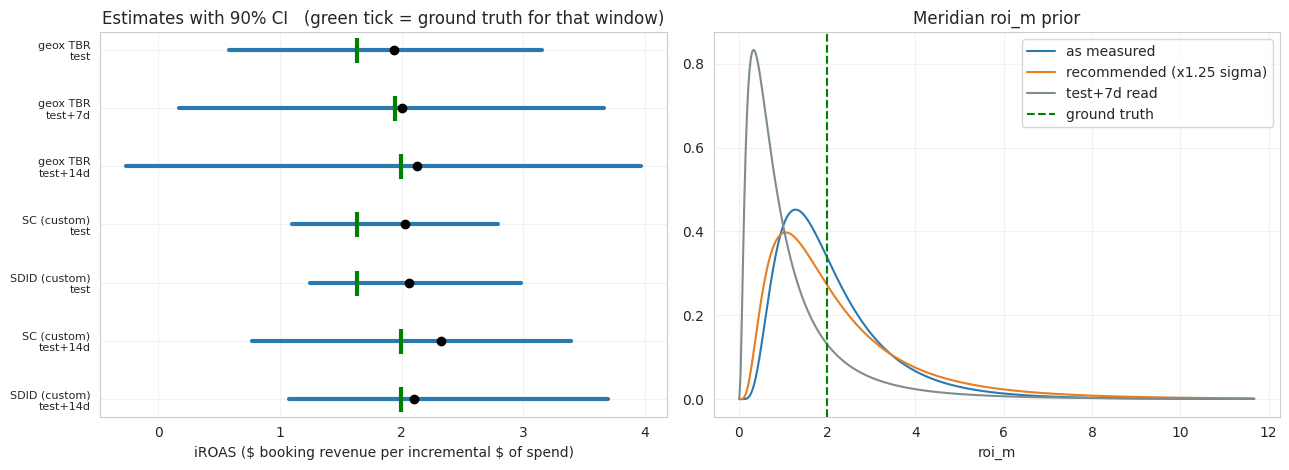

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
lab = [f"{r.method}\n{r.window}" for r in res.itertuples()]
y = np.arange(len(res))[::-1]
for yi, r in zip(y, res.itertuples()):
    ax[0].plot([r.iROAS_lo, r.iROAS_hi], [yi, yi], lw=3, color="#2a7ab0" if r.covers_truth else "#c0392b")
    ax[0].plot(r.iROAS, yi, "o", color="k")
    ax[0].plot(r.true_iROAS, yi, "|", color="green", ms=18, mew=3)
ax[0].set_yticks(y); ax[0].set_yticklabels(lab, fontsize=8); ax[0].set_xlabel(r"iROAS (\$ booking revenue per incremental \$ of spend)")
ax[0].set_title("Estimates with 90% CI   (green tick = ground truth for that window)")
xs = np.linspace(0.01, max(6.0, float(prior_w.quantile(0.995))), 400)
for d, nm, c in ((prior_q, "as measured", "#2a7ab0"), (prior_w, "recommended (x1.25 sigma)", "#e67e22"),
                 (prior_7, "test+7d read", "#7f8c8d")):
    ax[1].plot(xs, d.prob(xs), label=nm, color=c)
ax[1].axvline(truth["realised_iroas_lifetime"], color="green", ls="--", label="ground truth")
ax[1].set_xlabel("roi_m"); ax[1].set_title("Meridian roi_m prior"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT / "estimators_and_prior.png", dpi=120)

#### Verification

In [31]:
g = res[res.method == "geox TBR"].set_index("window")
prior_ok = (abs(float(prior_q.quantile(0.05)) / m.lower_bound - 1) < 0.01 and abs(float(prior_q.quantile(0.95)) / m.upper_bound - 1) < 0.01
            if how_q == "range-matched" else
            abs(float(prior_q.mean()) / m.point_estimate - 1) < 0.01 and abs(float(prior_q.stddev()) / m.standard_deviation - 1) < 0.01)
checks = {
    "geox TBR detects the effect in the powered window (test, p<0.10)": g.loc["test", "p_value"] < ALPHA,
    "geox TBR 90% CI covers ground truth: test window": bool(g.loc["test", "covers_truth"]),
    "geox TBR 90% CI covers ground truth: test+14d": bool(g.loc["test+14d", "covers_truth"]),
    "geox TBR lag effect visible: test-only truth < lifetime truth": T_ROAS["test"] < T_ROAS["test+14d"],
    "geox TBR test+14d iROAS within 35% of lifetime truth": abs(prim.iROAS / truth["realised_iroas_lifetime"] - 1) < 0.35,
    "geox TBR CI ordered & finite": bool(np.isfinite(g[["iROAS_lo", "iROAS", "iROAS_hi"]]).all().all()
                                         and (g.iROAS_lo <= g.iROAS).all() and (g.iROAS <= g.iROAS_hi).all()),
    "custom SC/SDID: placebo nulls centred (|mean| < 0.5 sd)": bool(
        all(abs(np.mean(v)) < 0.5 * np.std(v) for v in plc.values())),
    "custom SC/SDID: every CI contains its own point estimate": bool(
        ((res.iROAS_lo <= res.iROAS) & (res.iROAS <= res.iROAS_hi)).all()),
    f"prior reproduces experiment estimate ({how_q})": bool(prior_ok),
    "PriorDistribution / ModelSpec constructed": isinstance(model_spec, spec.ModelSpec),
}
banner("VERIFICATION")
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
print(f"[INFO] 90% intervals covering the window-specific ground truth: {int(res.covers_truth.sum())}/{len(res)} "
      f"(a single simulated test cannot validate calibration - expect ~1 miss in 10 over many tests)")
print(f"[INFO] p-values (test window): " + ", ".join(f"{r.method}={r.p_value:.3f}" for r in res[res.window == 'test'].itertuples()))
print(f"[INFO] p-values (test+14d)   : " + ", ".join(f"{r.method}={r.p_value:.3f}" for r in res[res.window == 'test+14d'].itertuples()))
assert all(checks.values()), "stage-4 verification failed"


VERIFICATION
[PASS] geox TBR detects the effect in the powered window (test, p<0.10)
[PASS] geox TBR 90% CI covers ground truth: test window
[PASS] geox TBR 90% CI covers ground truth: test+14d
[PASS] geox TBR lag effect visible: test-only truth < lifetime truth
[PASS] geox TBR test+14d iROAS within 35% of lifetime truth
[PASS] geox TBR CI ordered & finite
[PASS] custom SC/SDID: placebo nulls centred (|mean| < 0.5 sd)
[PASS] custom SC/SDID: every CI contains its own point estimate
[PASS] prior reproduces experiment estimate (moment-matched)
[PASS] PriorDistribution / ModelSpec constructed
[INFO] 90% intervals covering the window-specific ground truth: 7/7 (a single simulated test cannot validate calibration - expect ~1 miss in 10 over many tests)
[INFO] p-values (test window): geox TBR=0.002, SC (custom)=0.007, SDID (custom)=0.007
[INFO] p-values (test+14d)   : geox TBR=0.234, SC (custom)=0.007, SDID (custom)=0.033


## Reading the results
* The 28-day test window alone under-states iROAS (≈ 18 % of bookings land after the test ends); reading test + 14 d recovers it but widens the TBR interval.
* A single simulated test with one seed cannot validate interval calibration; repeat over seeds before trusting coverage claims.
* A heavy-up measures **marginal** iROAS of the extra spend, usually below the **average** ROI that Meridian's `roi_m` represents. The prior is therefore widened (σ × 1.25).
* Platform execution checklist (Google Ads / Meta Ads) and the hospitality hyperparameter rationale: see `README.md`.